# DeFi Yield Aggregator with an ML Forensic Risk Engine — Proof-of-Process (pure Python)

This notebook implements the **implementation plan** end-to-end **without any on-chain component**. Everything that would be a Solidity contract, keeper network or fork simulator is replaced by a small, tested Python model, so the *process* (data → features → labels → models → gate → fork dry-run → vault → keeper → feedback loop) can be demonstrated and validated offline.

| Plan step | Where it lives here |
|---|---|
| 1 Feature store | §2 `build_features` (point-in-time, vectorised) |
| 2 Labeled dataset | §2 `match_incidents`, `label_rows` (forward window + post-incident quarantine) |
| 3 Train classifier + anomaly detector | §3 `ForensicEngine` |
| 4 Validate on held-out *time*, incident-level | §3 `evaluate_holdout` |
| 5 Gate = hard rules floor + model score + 3 tiers | §3 `hard_rule_flags`, `ForensicEngine.decide` |
| 6 Fork simulation dry-run | §4 `fork_dry_run` (stress scenarios on a vault copy) |
| 7 Vault contract | §4 `SimVault` (ERC-4626-style shares, roles, pause, slippage, reentrancy guard, atomic reverts) |
| 8 Keeper-triggered execution | §5 `Keeper`, `plan_moves` |
| 9 Testnet / audit | §7 unit + property tests, injected exploit scenarios |
| 10 Monitoring + retraining loop | §8 drift (PSI), decision log, human-feedback queue, `train_pipeline` re-run |

**Token/cost guard.** `USE_REAL_DATA = False` and `ALLOW_NETWORK = False` by default. The notebook runs on a **synthetic universe** with planted, noisy exploit precursors. Nothing touches the network unless you flip *both* flags yourself.

**Honest-reading note.** Synthetic results verify that the *machinery works* (no look-ahead, caps hold, vault invariants hold, gate blocks planted precursors). They are **not evidence of real-world exploit-prediction skill**. That requires running on real data (§9).

## 0 · Setup and configuration
All tunables live in one dataclass. Design rationale for the main ones:

* **Time-based split with purge** (train → purge → val → purge → test): labels look 7 days *forward*, so rows within 7 days before a cut-off would leak future information (López de Prado, *Advances in Financial ML*, ch. 7 "purging").
* **Validation set is separate from test**: thresholds are calibrated on validation negatives; the test period is touched once.
* **Quarantine** after an incident: post-exploit rows (TVL crash, erratic APY) are *not* "normal"; labelling them 0 would teach the anomaly model that wreckage is normal.

In [1]:
from __future__ import annotations
import copy, functools, json, re, sys, time, warnings
from collections import defaultdict
from dataclasses import dataclass, replace
from difflib import get_close_matches
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score

try:
    from IPython.display import display
except ImportError:  # plain python
    display = print
warnings.filterwarnings("ignore", category=FutureWarning)


@dataclass
class Config:
    # ---- data source guards (both must be True to touch the network) ----
    USE_REAL_DATA: bool = True
    ALLOW_NETWORK: bool = True
    MAX_POOLS: int = 600
    MIN_TVL_FETCH: float = 1_000_000
    REQUEST_DELAY: float = 0.25
    MAX_REQUESTS: int = 900              # hard cap on LIVE calls per run (cache hits are free)
    FORCE_INCLUDE_HACKED: bool = True    # also fetch every catalogue pool of a hacked project
    EXTRA_HACKED_POOLS: int = 150
    MIN_HISTORY_DAYS: int = 45           # pools with fewer observed days are dropped
    APY_SANITY_MAX: float = 10_000.0     # rows above this are treated as data errors
    EXCLUDE_FEATURES: tuple = ()         # real data: consider ("log_tvl",) -- see section 9
    ARTIFACT_DIR: str = "artifacts"
    SEED: int = 42
    # ---- synthetic universe ----
    N_PROJECTS: int = 40
    DAYS: int = 540
    N_INCIDENTS: int = 16
    # ---- labels / splits ----
    LOOKAHEAD_DAYS: int = 7
    COOLDOWN_DAYS: int = 30
    TRAIN_FRAC: float = 0.55
    VAL_FRAC: float = 0.20
    PURGE_DAYS: int = 7
    # ---- models ----
    MIN_POS_ROWS: int = 30
    MIN_POS_INCIDENTS: int = 5
    INCIDENT_WEIGHT_FRAC: float = 0.02   # each incident's total weight = 2% of negative mass
    BLOCK_FPR: float = 0.005             # val-negative false-positive budget for auto-block
    SIM_FPR: float = 0.02                # val-negative false-positive budget for mandatory fork-sim band
    # ---- hard-rule floor ----
    MAX_APY_PCT: float = 500.0
    MIN_TVL_USD: float = 500_000.0
    MAX_POOL_7D_DRAWDOWN: float = -0.30
    MAX_PROTO_7D_DRAWDOWN: float = -0.25
    # ---- allocation ----
    CAPITAL_USD: float = 1_000_000.0
    REWARD_HAIRCUT: float = 0.5          # reward-token APY counted at 50%
    APY_RANK_CAP: float = 50.0
    MIN_APY: float = 1.0
    RISK_AVERSION: float = 0.75
    POOL_CAP: float = 0.15
    PROTO_CAP: float = 0.25
    TVL_SHARE_CAP: float = 0.02          # never be >2% of a pool's TVL
    MAX_POSITIONS: int = 20
    # ---- execution / keeper ----
    MIN_TRADE_USD: float = 1_000.0
    REBALANCE_EVERY_DAYS: int = 7
    REBALANCE_HORIZON_DAYS: int = 30
    HURDLE_MULT: float = 2.0             # expected gain must exceed 2x costs
    DEX_DEPTH_USD: float = 100_000_000.0
    DEX_FEE_BPS: float = 30.0
    WITHDRAW_FEE_BPS: float = 5.0
    MAX_MOVE_LOSS_BPS: float = 150.0
    # ---- paper-world exploit model (assumption) ----
    EXPLOIT_LOSS_FRACTION: float = 0.8


CFG = Config()
ARTIFACTS = Path(CFG.ARTIFACT_DIR); ARTIFACTS.mkdir(exist_ok=True)
ALL_FEATURES = [
    "apy", "log_tvl", "tvl_ret_1", "tvl_ret_7", "tvl_ret_30", "tvl_dd_30",
    "apy_delta_7", "apy_vol_7", "apy_z_30", "apy_ratio_30", "reward_share",
    "apy_xs_pct", "proto_tvl_ret_7", "proto_tvl_dd_30",
]
FEATURES = [f for f in ALL_FEATURES if f not in CFG.EXCLUDE_FEATURES]   # what the models see
print(f"USE_REAL_DATA={CFG.USE_REAL_DATA}  ALLOW_NETWORK={CFG.ALLOW_NETWORK}  -> "
      + ("REAL data from cache/network" if CFG.USE_REAL_DATA else "synthetic universe (no network)"))

USE_REAL_DATA=True  ALLOW_NETWORK=True  -> REAL data from cache/network


## 1 · Data layer (synthetic by default)
`make_synthetic_universe` produces the **same schema** as the DeFiLlama pipeline: `pool, project, symbol, timestamp, tvlUsd, apy, apyBase, apyReward`, plus a hack feed in DeFiLlama's shape (`name, date[unix s], amount, chain`).

Planted realism so the pipeline is genuinely stressed:
* AR(1)/Ornstein-Uhlenbeck APY with project-level TVL factor (pools of one protocol co-move);
* **30% of incidents have no precursor at all** (unpredictable), the rest have a noisy 7-day ramp (APY spike plus either a TVL "hype pump" or a slow "bleed");
* **benign APY spikes** on non-exploited pools (false-positive traps);
* 2% missing rows, name variants in the hack feed (one needs a *reviewed alias*), and decoy events for protocols not in the universe.

`fetch_real_data` is the real DeFiLlama loader (resumable cache, request cap, hacked-project pool inclusion, id-based hack matching). The network is touched only on a cache miss with `ALLOW_NETWORK=True`. `MockDefiLlama` serves fake, messy, DeFiLlama-shaped payloads so the whole real path is rehearsed offline in §7 (no real data, no network).

In [2]:
HEADERS = {"User-Agent": "defi-forensic-proof-of-process/2.0"}


def parse_dates(values: pd.Series) -> pd.Series:
    """Accept unix s, unix ms or ISO strings -> tz-aware UTC."""
    if pd.api.types.is_datetime64_any_dtype(values):
        return pd.to_datetime(values, utc=True)
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().mean() > 0.8:
        unit = "ms" if numeric.dropna().abs().median() > 1e12 else "s"
        return pd.to_datetime(numeric, unit=unit, utc=True, errors="coerce")
    return pd.to_datetime(values, utc=True, errors="coerce")


def to_day_num(ts: pd.Series) -> np.ndarray:
    """tz-aware timestamps -> integer day number (days since epoch, UTC)."""
    return ts.dt.tz_convert("UTC").dt.tz_localize(None).values.astype("datetime64[D]").astype("int64")


def make_synthetic_universe(cfg: Config):
    rng = np.random.default_rng(cfg.SEED)
    T = cfg.DAYS
    days = pd.date_range("2025-01-01", periods=T, freq="D", tz="UTC")
    symbols = np.array(["USDC", "USDT", "DAI", "WETH", "WBTC", "stETH"])
    projects = [f"proto-{i:02d}" for i in range(cfg.N_PROJECTS)]
    assert cfg.N_INCIDENTS <= cfg.N_PROJECTS

    # ---- planted incidents (ground truth lives ONLY here; pipeline never reads it) ----
    ev_days = np.linspace(70, T - 12, cfg.N_INCIDENTS).astype(int) + rng.integers(-4, 5, cfg.N_INCIDENTS)
    ev_days = np.clip(ev_days, 40, T - 10)
    ev_projects = rng.choice(projects, size=cfg.N_INCIDENTS, replace=False)
    spec = {}
    for p, d in zip(ev_projects, ev_days):
        detectable = rng.random() < 0.7
        spec[p] = dict(day=int(d), strength=float(rng.uniform(0.6, 1.5)) if detectable else 0.0,
                       mode=str(rng.choice(["hype", "bleed"])), drop=float(rng.uniform(0.6, 0.95)))

    meta_rows, tvl_l, apy_l, rew_l = [], [], [], []
    t_idx = np.arange(T)
    for p in projects:
        n_pools = int(rng.integers(2, 6))
        proj_walk = np.cumsum(rng.normal(0, 0.02, T))
        proj_mult, apy_mult = np.ones(T), np.ones(T)
        s = spec.get(p)
        if s:
            d, w = s["day"], cfg.LOOKAHEAD_DAYS
            ramp = np.clip((t_idx - (d - w)) / w, 0, 1) * (t_idx < d)
            apy_mult = apy_mult * (1 + 2.5 * s["strength"] * ramp)
            proj_mult = proj_mult * ((1 + 0.15 * s["strength"] * ramp) if s["mode"] == "hype"
                                     else (1 - 0.20 * s["strength"] * ramp))
            post = t_idx >= d
            proj_mult = np.where(post, proj_mult * (1 - s["drop"]), proj_mult)
            apy_mult = np.where(post, 0.3, apy_mult)
        base_tvl = rng.lognormal(18.0, 1.0)
        reward_share = rng.uniform(0.0, 0.7)
        for k in range(n_pools):
            tvl = base_tvl * rng.uniform(0.15, 1.0) * np.exp(proj_walk + np.cumsum(rng.normal(0, 0.01, T))) * proj_mult
            mu = rng.lognormal(1.5, 0.6)
            noise = rng.normal(0, 0.15 * mu + 0.1, T)
            x = np.empty(T); x[0] = mu
            for t in range(1, T):
                x[t] = x[t - 1] + 0.08 * (mu - x[t - 1]) + noise[t]
            x = np.clip(x, 0.05, None)
            if (not s) and rng.random() < 0.3:          # benign spike (false-positive trap)
                b = int(rng.integers(40, T - 5)); x[b:b + 3] *= 3.0
            x = x * apy_mult
            meta_rows.append(dict(pool=f"{p}-pool{k}", project=p, symbol=str(rng.choice(symbols))))
            tvl_l.append(tvl); apy_l.append(x); rew_l.append(x * reward_share)

    meta = pd.DataFrame(meta_rows)
    n = len(meta)
    tvl, apy, rew = np.vstack(tvl_l), np.vstack(apy_l), np.vstack(rew_l)
    ts = pd.to_datetime(np.tile(days.tz_convert(None).values, n), utc=True)
    hist = pd.DataFrame({
        "pool": np.repeat(meta.pool.values, T), "project": np.repeat(meta.project.values, T),
        "symbol": np.repeat(meta.symbol.values, T), "timestamp": ts,
        "tvlUsd": tvl.ravel(), "apy": apy.ravel(), "apyReward": rew.ravel(),
    })
    hist["apyBase"] = hist["apy"] - hist["apyReward"]
    hist = hist.loc[rng.random(len(hist)) > 0.02].reset_index(drop=True)

    # ---- hack feed in DeFiLlama shape ----
    hacks, aliases = [], {}
    for i, (p, sp) in enumerate(spec.items()):
        name = p.replace("-", " ").title()                 # "Proto 03" -> normalises to proto03
        if i == 2:                                         # needs a reviewed alias
            name = f"{p} Finance"; aliases[name] = p
        hacks.append(dict(name=name, date=int(days[sp["day"]].timestamp()), amount=float(sp["drop"] * 1e7), chain="Ethereum"))
    for j in range(25):                                    # decoys
        hacks.append(dict(name=f"Unlisted Protocol {j}", date=int(days[int(rng.integers(0, T))].timestamp()), amount=1e6, chain="BSC"))
    hacks.append(dict(name="Proto 99", date=int(days[100].timestamp()), amount=5e5, chain="Ethereum"))
    return hist, hacks, aliases, meta, spec


def normalize_name(s) -> str:
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


class BudgetExceeded(RuntimeError):
    pass


def fetch_real_data(cfg: Config):
    """REAL DeFiLlama loader.

    Cost-safety design (why it is built this way)
    * USE_REAL_DATA must be True.  The network is touched ONLY on a cache miss and ONLY if
      ALLOW_NETWORK is True; otherwise a RuntimeError says exactly what is missing.
      => fetch once, then set ALLOW_NETWORK=False and rerun offline for free.
    * Every response is written to disk before the next call (crash-resumable).
    * MAX_REQUESTS is a hard cap on live calls per run; hitting it keeps the cache and returns a
      PARTIAL universe with a loud warning (never silently).

    Selection-bias design (the hard part of real data)
    * The yields catalogue lists only CURRENTLY listed pools. Pools of exploited protocols are often
      drained/delisted, so a plain "top-N by current TVL" universe contains almost no victims.
      FORCE_INCLUDE_HACKED therefore also fetches every catalogue pool of a hacked project (matched
      through the hack feed's own defillamaId, with name matching as a fallback).
    * Hacks are tied to pools through DeFiLlama ids (protocol id -> slug, parent id -> child slugs),
      because hack display names ("Euler Finance") rarely equal pool project slugs ("euler").
    """
    if not cfg.USE_REAL_DATA:
        raise RuntimeError("Real data disabled. Set CFG.USE_REAL_DATA=True (and ALLOW_NETWORK=True for the first fetch).")
    import requests
    from urllib.parse import quote
    raw = Path(cfg.ARTIFACT_DIR) / "raw"; (raw / "charts").mkdir(parents=True, exist_ok=True)
    stats = dict(live=0, cached=0)

    def get(url, path):
        if path.exists():
            stats["cached"] += 1
            return json.loads(path.read_text(encoding="utf-8"))
        if not cfg.ALLOW_NETWORK:
            raise RuntimeError(f"Cache miss for '{path.name}' and CFG.ALLOW_NETWORK is False. "
                               "Set ALLOW_NETWORK=True once to populate the cache.")
        if stats["live"] >= cfg.MAX_REQUESTS:
            raise BudgetExceeded(f"MAX_REQUESTS={cfg.MAX_REQUESTS} reached; cache kept, rerun to resume or raise the cap.")
        for attempt in range(3):
            try:
                r = requests.get(url, headers=HEADERS, timeout=30); r.raise_for_status(); data = r.json(); break
            except (requests.RequestException, ValueError):
                if attempt == 2: raise
                time.sleep(2 ** attempt)
        stats["live"] += 1
        path.write_text(json.dumps(data), encoding="utf-8"); time.sleep(cfg.REQUEST_DELAY)
        return data

    hacks = get("https://api.llama.fi/hacks", raw / "hacks.json")
    hacks = hacks.get("data", hacks) if isinstance(hacks, dict) else hacks
    protocols = get("https://api.llama.fi/protocols", raw / "protocols.json")
    protocols = protocols.get("protocols", protocols) if isinstance(protocols, dict) else protocols
    id_to_slugs = defaultdict(set)
    for p in protocols:
        if isinstance(p, dict) and p.get("slug"):
            id_to_slugs[str(p.get("id"))].add(p["slug"])
            if p.get("parentProtocol"):
                id_to_slugs[str(p["parentProtocol"])].add(p["slug"])
    for h in hacks:
        key = h.get("defillamaId")
        h["projects_hint"] = sorted(id_to_slugs.get(str(key), [])) if key not in (None, "") else []

    cat = get("https://yields.llama.fi/pools", raw / "pool_catalog.json")
    pools = pd.DataFrame(cat.get("data", cat) if isinstance(cat, dict) else cat)
    pools["tvlUsd"] = pd.to_numeric(pools["tvlUsd"], errors="coerce")
    pools = pools.dropna(subset=["pool", "project"]).drop_duplicates("pool")
    sel = (pools.dropna(subset=["tvlUsd"]).loc[lambda f: f.tvlUsd >= cfg.MIN_TVL_FETCH]
           .sort_values("tvlUsd", ascending=False).head(cfg.MAX_POOLS))
    if cfg.FORCE_INCLUDE_HACKED:
        hinted = {s for h in hacks for s in h.get("projects_hint", [])}
        named = {normalize_name(h.get("name", "")) for h in hacks} - {""}
        mine = pools[pools.project.isin(hinted) | pools.project.map(normalize_name).isin(named)]
        sel = pd.concat([sel, mine.sort_values("tvlUsd", ascending=False).head(cfg.EXTRA_HACKED_POOLS)]).drop_duplicates("pool")

    rows, failed, truncated = [], [], False
    for r in sel.itertuples(index=False):
        try:
            payload = get(f"https://yields.llama.fi/chart/{quote(str(r.pool), safe='')}", raw / "charts" / f"{r.pool}.json")
        except BudgetExceeded as e:
            print("WARNING - PARTIAL UNIVERSE:", e); truncated = True; break
        except requests.RequestException:
            failed.append(str(r.pool)); continue
        obs = payload.get("data", payload) if isinstance(payload, dict) else payload
        sym = str(getattr(r, "symbol", ""))
        rows += [dict(pool=str(r.pool), project=str(r.project), symbol=sym, timestamp=o.get("timestamp"),
                      tvlUsd=o.get("tvlUsd"), apy=o.get("apy"), apyBase=o.get("apyBase"), apyReward=o.get("apyReward"))
                 for o in obs if isinstance(o, dict)]
    hist = pd.DataFrame(rows, columns=["pool", "project", "symbol", "timestamp", "tvlUsd", "apy", "apyBase", "apyReward"])
    meta = sel[["pool", "project"]].assign(symbol=sel["symbol"] if "symbol" in sel else "").astype(str).reset_index(drop=True)
    print(f"real-data loader: live requests={stats['live']} cache hits={stats['cached']} pools={len(sel)} "
          f"(forced hacked-project pools included) failed={len(failed)} truncated={truncated}")
    return hist, hacks, {}, meta, None


def clean_history(h: pd.DataFrame, cfg: Config):
    """Defensive cleaning for messy real payloads. Must be a no-op on the synthetic universe."""
    rep = {"rows_in": len(h)}
    h = h.copy()
    h["timestamp"] = parse_dates(h["timestamp"])
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        h[c] = pd.to_numeric(h[c], errors="coerce") if c in h else np.nan
    bad = h.timestamp.isna() | ~(h.tvlUsd > 0) | h.apy.isna() | ~(h.apy >= 0) | (h.apy > cfg.APY_SANITY_MAX)
    rep["dropped_invalid"] = int(bad.sum()); h = h[~bad]
    h["_day"] = to_day_num(h["timestamp"])
    n0 = len(h)
    h = h.sort_values(["pool", "timestamp"]).drop_duplicates(["pool", "_day"], keep="last")
    rep["dropped_duplicate_days"] = n0 - len(h)
    short = h.groupby("pool")["_day"].transform("nunique") < cfg.MIN_HISTORY_DAYS
    rep["dropped_short_history_pools"] = int(h.loc[short, "pool"].nunique()); h = h[~short]
    rep["rows_out"] = len(h)
    return h.drop(columns="_day").reset_index(drop=True), rep


class _Resp:
    def __init__(self, body): self._b = json.loads(json.dumps(body))
    def raise_for_status(self): pass
    def json(self): return self._b


class MockDefiLlama:
    """Serves DeFiLlama-SHAPED payloads built from the synthetic universe, with the messiness real
    endpoints have. Contains NO real data and makes NO network call; used to rehearse the real-data
    path (fetch -> cache -> clean -> id-join -> labels) before spending a single real request.
    Quirks planted: time-of-day ISO timestamps, null apyBase/apyReward, a duplicated day, a garbage
    5e7 % APY row, a 10-day hole, a too-short history, hack names that do NOT match project slugs
    (only the defillamaId join can recover them), a parent->child protocol family, and hacked
    projects whose catalogue TVL is tiny (survivorship trap)."""
    def __init__(self, cfg: Config):
        h, hk, _, meta, spec = make_synthetic_universe(cfg)
        rng = np.random.default_rng(cfg.SEED + 1)
        self.spec, self.calls, self.expect = spec, [], {}
        hacked = list(spec)
        others = sorted(set(meta.project) - set(hacked))
        ids = {p: str(1000 + i) for i, p in enumerate(sorted(meta.project))}
        self.protocols = [dict(id=ids[p], name=p.title(), slug=p) for p in ids]
        fam_child = others[0]                          # an un-hacked sibling of hacked[0]
        for q in self.protocols:
            if q["slug"] in (hacked[0], fam_child): q["parentProtocol"] = "parent#fam"
        self.protocols.append(dict(id="parent#fam", name="Family", slug="family"))
        self.feed = []
        for i, p in enumerate(hacked):
            self.feed.append(dict(name=f"Unrelated Brand {i}", date=hk[i]["date"], amount=1e6, chain="Ethereum",
                                  defillamaId="parent#fam" if i == 0 else ids[p], classification="Protocol Logic"))
        self.feed.append(dict(name="Orphan Bridge", date=hk[0]["date"], amount=1e6, chain="BSC", defillamaId="999999"))
        self.rows, cat = {}, []
        for pool, g in h.groupby("pool"):
            recs = []
            for t, tv, a, ab, ar in zip(g.timestamp, g.tvlUsd, g.apy, g.apyBase, g.apyReward):
                ts = (t + pd.Timedelta(hours=23, minutes=1, seconds=36)).strftime("%Y-%m-%dT%H:%M:%S.000Z")
                recs.append(dict(timestamp=ts, tvlUsd=float(tv), apy=float(a),
                                 apyBase=None if rng.random() < 0.05 else float(ab),
                                 apyReward=None if rng.random() < 0.30 else float(ar), il7d=None))
            self.rows[pool] = recs
            proj = g.project.iloc[0]
            cat.append(dict(pool=pool, project=proj, symbol=g.symbol.iloc[0],
                            tvlUsd=10.0 if proj == hacked[0] else float(g.tvlUsd.iloc[-1])))
        self.catalog = cat
        q = sorted(meta.loc[meta.project.isin(hacked[:2]), "pool"])
        dup, gar, gap, short = q[0], q[1], q[2], q[3]
        self.rows[dup].append(dict(self.rows[dup][-1], timestamp=self.rows[dup][-1]["timestamp"].replace(":01:", ":59:")))
        self.rows[gar][50]["apy"] = 5e7
        day = lambda r: pd.Timestamp(r["timestamp"]).tz_convert("UTC").tz_localize(None).normalize()
        d_a = day(self.rows[gap][60])
        self.expect["gap_days"] = [int((d_a + pd.Timedelta(days=k)).value // 86_400_000_000_000) for k in range(10)]
        self.rows[gap] = [r for r in self.rows[gap] if not (d_a <= day(r) < d_a + pd.Timedelta(days=10))]
        self.rows[short] = self.rows[short][-20:]
        self.expect.update(gap_pool=gap, short_pool=short, garbage_pool=gar, hacked0=hacked[0], fam_child=fam_child)

    def get(self, url, headers=None, timeout=None):
        from urllib.parse import unquote
        self.calls.append(url)
        if url == "https://yields.llama.fi/pools": body = dict(status="success", data=self.catalog)
        elif url.startswith("https://yields.llama.fi/chart/"): body = dict(status="success", data=self.rows[unquote(url.split("/chart/", 1)[1])])
        elif url == "https://api.llama.fi/hacks": body = self.feed
        elif url == "https://api.llama.fi/protocols": body = self.protocols
        else: raise AssertionError(f"unexpected URL requested: {url}")
        return _Resp(body)


def run_offline_rehearsal(base: Config) -> dict:
    """Dress rehearsal of the REAL-data path against MockDefiLlama. Zero network, zero real data."""
    import tempfile
    from unittest import mock
    sim = replace(base, N_PROJECTS=12, DAYS=150, N_INCIDENTS=3, SEED=7)
    srv = MockDefiLlama(sim); out = {}
    with tempfile.TemporaryDirectory() as tmp, tempfile.TemporaryDirectory() as tmp2, tempfile.TemporaryDirectory() as tmp3:
        rc = replace(sim, USE_REAL_DATA=True, ALLOW_NETWORK=True, ARTIFACT_DIR=tmp, MAX_POOLS=10,
                     MIN_TVL_FETCH=1e6, REQUEST_DELAY=0.0, MAX_REQUESTS=500)
        with mock.patch("requests.get", srv.get):
            h, hk, al, meta, _ = fetch_real_data(rc)
            n1 = len(srv.calls)
            fetch_real_data(replace(rc, ALLOW_NETWORK=False))
            out["offline_rerun_uses_cache_only"] = len(srv.calls) == n1
            try: fetch_real_data(replace(rc, ALLOW_NETWORK=False, ARTIFACT_DIR=tmp2)); out["cold_cache_offline_refuses"] = False
            except RuntimeError: out["cold_cache_offline_refuses"] = True
            b0 = len(srv.calls); fetch_real_data(replace(rc, ARTIFACT_DIR=tmp3, MAX_REQUESTS=5))
            out["request_budget_enforced"] = len(srv.calls) - b0 <= 5
        hot = srv.expect["hacked0"]
        out["force_include_low_tvl_hacked_pools"] = {p["pool"] for p in srv.catalog if p["project"] == hot} <= set(meta.pool)
        hc, rep = clean_history(h, rc)
        out["garbage_apy_dropped"] = rep["dropped_invalid"] >= 1 and float(hc.apy.max()) <= rc.APY_SANITY_MAX
        out["duplicate_day_dropped"] = rep["dropped_duplicate_days"] >= 1
        out["short_history_pool_dropped"] = srv.expect["short_pool"] not in set(hc.pool)
        f = build_features(hc, rc)
        days = set(f.loc[f.pool == srv.expect["gap_pool"], "day_num"])
        out["gap_not_papered_over"] = not (set(srv.expect["gap_days"][3:]) & days)
        inc, _ = match_incidents(hk, f.project.unique(), (int(f.day_num.min()), int(f.day_num.max())), al)
        out["id_join_recovers_incidents_and_family"] = (len(inc) == len(srv.spec) + 1 and set(inc.match_method) == {"defillama id"}
                                                        and srv.expect["fam_child"] in set(inc.project))
        lab = label_rows(f, inc, rc)
        out["labels_exist_on_rehearsal"] = int(lab.label.sum()) > 0
    return out


def load_universe(cfg: Config):
    return fetch_real_data(cfg) if cfg.USE_REAL_DATA else make_synthetic_universe(cfg)

In [3]:
hist, hacks, ALIASES, meta, _truth = load_universe(CFG)
hist, clean_report = clean_history(hist, CFG)
print(f"history rows={len(hist):,}  pools={hist.pool.nunique()}  projects={hist.project.nunique()}  hack-feed events={len(hacks)}")
print("cleaning report:", clean_report)
display(hist.head(3))

real-data loader: live requests=602 cache hits=0 pools=600 (forced hacked-project pools included) failed=1 truncated=False
history rows=305,555  pools=546  projects=162  hack-feed events=1328
cleaning report: {'rows_in': 306590, 'dropped_invalid': 68, 'dropped_duplicate_days': 136, 'dropped_short_history_pools': 53, 'rows_out': 305555}


,pool,project,symbol,timestamp,tvlUsd,apy,apyBase,apyReward
0,007d03bd-4987-4b3b-b7d2-2f3af42fa4b4,compound-v3,WSTETH,2024-10-03 23:01:24.049+00:00,52098522,0.0,NaN,NaN
1,007d03bd-4987-4b3b-b7d2-2f3af42fa4b4,compound-v3,WSTETH,2024-10-04 23:17:18.759+00:00,53720429,0.0,NaN,NaN
2,007d03bd-4987-4b3b-b7d2-2f3af42fa4b4,compound-v3,WSTETH,2024-10-05 23:17:46.600+00:00,53522812,0.0,NaN,NaN


## 2 · Feature store and labels (plan steps 1–2)

**Features** are *point-in-time*: every value at day *t* uses only data ≤ *t* (verified by a look-ahead test in §7). Compared with the original notebook the set is richer and closer to the plan's list (TVL change, oracle/price-divergence stand-ins, utilisation stand-ins):

| Feature | Rationale |
|---|---|
| `tvl_ret_{1,7,30}`, `tvl_dd_30` | liquidity flight / drawdown from 30-day peak |
| `apy_z_30`, `apy_ratio_30` | APY vs its *own lagged* 30-day baseline (lag avoids self-dampening) |
| `apy_delta_7`, `apy_vol_7` | rate instability |
| `reward_share` | incentive-driven yield is fragile and often precedes rug/depeg |
| `apy_xs_pct` | cross-sectional rank among all pools that day (anomalous yield relative to market) |
| `proto_tvl_ret_7`, `proto_tvl_dd_30` | **protocol-level** TVL (sum over pools, forward-filled ≤3 days so missing rows don't fake a drop) |

**Labels**: positives = rows of the incident's protocol in `[event − 7d, event)`. Rows in `[event, event+30d)` are **quarantined** (excluded from training and evaluation). Only exact-normalised names or a *reviewed* alias auto-match; fuzzy candidates are emitted for human review, never auto-accepted.

In [4]:
def build_features(history: pd.DataFrame, cfg: Config = CFG) -> pd.DataFrame:
    df = history.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.floor("D")
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        df[c] = pd.to_numeric(df[c], errors="coerce") if c in df else np.nan
    df = df.dropna(subset=["tvlUsd", "apy"])
    df = df[(df.tvlUsd > 0) & (df.apy >= 0)]
    df["apyReward"] = df["apyReward"].fillna(0.0).clip(lower=0)
    df["apyBase"] = df["apyBase"].fillna(df["apy"] - df["apyReward"]).clip(lower=0)
    df["day_num"] = to_day_num(df["timestamp"])
    df = df.sort_values(["pool", "day_num"]).drop_duplicates(["pool", "day_num"], keep="last").reset_index(drop=True)
    # Dense daily grid per pool. Row-based lags (shift(7), pct_change(30)) are only calendar-correct if
    # every day has a row. Gaps <=3 days are forward-filled (past values only); longer gaps stay NaN so
    # no feature is ever computed across a hole. (Academic rationale: avoid silently mis-specified lags.)
    span = df.groupby("pool", sort=False)["day_num"].agg(["min", "max"])
    span["max"] = int(df["day_num"].max())      # every pool is carried to the as-of day: row set never depends on a pool's own future
    grid = pd.DataFrame({"pool": np.repeat(span.index.values, (span["max"] - span["min"] + 1).values),
                         "day_num": np.concatenate([np.arange(a, b + 1) for a, b in zip(span["min"], span["max"])])})
    const = df.drop_duplicates("pool")[["pool", "project", "symbol"]]
    df = (grid.merge(df.drop(columns=["project", "symbol", "timestamp"]), on=["pool", "day_num"], how="left")
              .merge(const, on="pool", how="left"))
    vcols = ["tvlUsd", "apy", "apyBase", "apyReward"]
    df[vcols] = df.groupby("pool", sort=False)[vcols].ffill(limit=3)
    df["timestamp"] = pd.to_datetime(df["day_num"], unit="D", utc=True)
    df["apy_eff"] = df["apyBase"] + cfg.REWARD_HAIRCUT * df["apyReward"]

    df["log_tvl"] = np.log1p(df["tvlUsd"])
    df["_apy_lag"] = df.groupby("pool", sort=False)["apy"].shift(1)
    g = df.groupby("pool", sort=False)

    def roll(col, w, fn, mp):
        return getattr(g[col].rolling(w, min_periods=mp), fn)().reset_index(level=0, drop=True)

    for k in (1, 7, 30):
        df[f"tvl_ret_{k}"] = g["tvlUsd"].pct_change(k, fill_method=None).clip(-1, 10)
    df["tvl_dd_30"] = df["tvlUsd"] / roll("tvlUsd", 30, "max", 5) - 1
    m30, s30 = roll("_apy_lag", 30, "mean", 10), roll("_apy_lag", 30, "std", 10)
    df["apy_z_30"] = ((df["apy"] - m30) / (s30 + 1e-6)).clip(-10, 10)
    df["apy_ratio_30"] = (df["apy"] / (m30 + 1e-6)).clip(0, 20)
    df["apy_delta_7"] = g["apy"].diff(7)
    df["apy_vol_7"] = roll("apy", 7, "std", 3)
    df["reward_share"] = (df["apyReward"] / (df["apy"] + 1e-6)).clip(0, 1)
    df["apy_xs_pct"] = df.groupby("day_num")["apy"].rank(pct=True)

    # protocol-level TVL (forward-fill <=3 days so missing rows do not create fake drops)
    wide = df.pivot(index="day_num", columns="pool", values="tvlUsd").sort_index()
    wide = wide.reindex(range(int(wide.index.min()), int(wide.index.max()) + 1)).ffill(limit=3)
    proj_of = df.drop_duplicates("pool").set_index("pool")["project"].reindex(wide.columns)
    proto = wide.T.groupby(proj_of.values).sum(min_count=1).T
    # like-for-like 7d protocol TVL change: only pools observed on BOTH dates, so a pool listing/delisting
    # does not masquerade as a protocol collapse and trip the hard rule.
    codes, uniq = pd.factorize(proj_of.values)
    W = wide.to_numpy(float); Wp = np.vstack([np.full((7, W.shape[1]), np.nan), W[:-7]])
    both = ~np.isnan(W) & ~np.isnan(Wp)
    M = np.zeros((W.shape[1], len(uniq))); M[np.arange(W.shape[1]), codes] = 1.0
    num, den = np.where(both, W, 0.0) @ M, np.where(both, Wp, 0.0) @ M
    ret7 = pd.DataFrame(np.where(den > 0, num / np.where(den > 0, den, 1.0) - 1, np.nan),
                        index=wide.index, columns=uniq).clip(-1, 10)
    dd30 = proto / proto.rolling(30, min_periods=5).max() - 1
    long = (ret7.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_ret_7")
            .merge(dd30.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_dd_30"),
                   on=["day_num", "project"]))
    df = df.merge(long, on=["day_num", "project"], how="left")
    df = df.drop(columns=["_apy_lag"]).replace([np.inf, -np.inf], np.nan).dropna(subset=ALL_FEATURES)
    return df.sort_values(["pool", "day_num"]).reset_index(drop=True)


def match_incidents(hack_feed, projects, day_range, aliases):
    ev = pd.DataFrame(hack_feed)
    name_col = next(c for c in ("name", "protocol", "project") if c in ev.columns)
    date_col = next(c for c in ("date", "timestamp", "time") if c in ev.columns)
    ev["event_name"] = ev[name_col].astype(str)
    ev["event_time"] = parse_dates(ev[date_col])
    ev = ev.dropna(subset=["event_time"]).reset_index(drop=True)
    ev["event_day"] = to_day_num(ev["event_time"])
    proj_norm = {normalize_name(p): p for p in projects}
    alias_norm = {normalize_name(k): v for k, v in aliases.items()}
    hints = ev["projects_hint"] if "projects_hint" in ev.columns else pd.Series([[]] * len(ev))
    pset, rows = set(projects), []     # one row per (event, project): a family-level hack hits every child slug
    for i, n in enumerate(ev.event_name):
        k = normalize_name(n); h = hints.iloc[i]; h = [p for p in h if p in pset] if isinstance(h, list) else []
        if k in alias_norm:   rows.append((i, alias_norm[k], "reviewed alias"))
        elif h:               rows += [(i, p, "defillama id") for p in h]
        elif k in proj_norm:  rows.append((i, proj_norm[k], "normalized exact name"))
        else:                 rows.append((i, None, ""))
    ev = ev.iloc[[r[0] for r in rows]].reset_index(drop=True)
    ev["project"], ev["match_method"] = [r[1] for r in rows], [r[2] for r in rows]
    in_range = ev.event_day.between(*day_range)
    matched = ev[ev.project.notna() & in_range].drop_duplicates(["project", "event_day"]).copy()
    matched["event_id"] = matched.project + "|" + matched.event_day.astype(str)
    review = ev[ev.project.isna() & in_range].copy()
    keys = list(proj_norm)
    review["suggested_project"] = [
        (proj_norm[m[0]] if (m := get_close_matches(normalize_name(n), keys, n=1, cutoff=0.75)) else "")
        for n in review.event_name]
    cols = ["project", "event_name", "event_time", "event_day", "event_id", "match_method"]
    return matched[cols].reset_index(drop=True), review[review.suggested_project != ""][["event_name", "event_time", "suggested_project"]]


def label_rows(feat: pd.DataFrame, incidents: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    out = feat.copy()
    d, proj = out.day_num.values, out.project.values
    label = np.zeros(len(out), np.int8); inc = np.full(len(out), "", dtype=object); quar = np.zeros(len(out), bool)
    for r in incidents.itertuples(index=False):
        m = proj == r.project
        pos = m & (d >= r.event_day - cfg.LOOKAHEAD_DAYS) & (d < r.event_day)
        quar |= m & (d >= r.event_day) & (d < r.event_day + cfg.COOLDOWN_DAYS)
        label[pos] = 1; inc[pos] = r.event_id
    label[quar] = 0
    out["label"], out["incident_id"], out["quarantine"] = label, inc, quar
    return out


def make_splits(feat: pd.DataFrame, cfg: Config):
    days = np.sort(feat.day_num.unique())
    t1 = int(days[int(len(days) * cfg.TRAIN_FRAC)]); t2 = int(days[int(len(days) * (cfg.TRAIN_FRAC + cfg.VAL_FRAC))])
    d, P = feat.day_num.values, cfg.PURGE_DAYS
    split = np.full(len(feat), "purge", dtype=object)
    split[d < t1 - P] = "train"; split[(d >= t1) & (d < t2 - P)] = "val"; split[d >= t2] = "test"
    return split, t1, t2


feat = build_features(hist)
incidents, review_queue = match_incidents(hacks, feat.project.unique(), (int(feat.day_num.min()), int(feat.day_num.max())), ALIASES)
feat = label_rows(feat, incidents, CFG)
feat["split"], T1, T2 = make_splits(feat, CFG)
incidents["split"] = np.where(incidents.event_day < T1, "train", np.where(incidents.event_day < T2, "val", "test"))

print(f"feature rows={len(feat):,}  positives={int(feat.label.sum())}  quarantined={int(feat.quarantine.sum())}")
print("matched incidents by split:", incidents.split.value_counts().to_dict(), "| match methods:", incidents.match_method.value_counts().to_dict())
print("unmatched events with a fuzzy suggestion (HUMAN REVIEW REQUIRED, not auto-accepted):")
display(review_queue.head())


def audit_universe(hist, feat, incidents, hacks, cfg):
    """Pre-training reality check. Prints what the data can and cannot support."""
    d0, d1 = int(feat.day_num.min()), int(feat.day_num.max())
    print(f"universe: {feat.pool.nunique()} pools / {feat.project.nunique()} projects | "
          f"{pd.to_datetime(d0, unit='D').date()} -> {pd.to_datetime(d1, unit='D').date()} | "
          f"median history {int(hist.groupby('pool').size().median())} d")
    print(f"hack feed: {len(hacks)} events | matched to universe & date range: {len(incidents)} "
          f"{incidents.match_method.value_counts().to_dict()}")
    by = feat[feat.label == 1].groupby("split").incident_id.nunique().to_dict()
    print("incidents with positive rows by split:", by)
    n_tr, n_te = by.get("train", 0), by.get("test", 0)
    if n_tr < cfg.MIN_POS_INCIDENTS:
        print(f"  ! only {n_tr} train incidents (< {cfg.MIN_POS_INCIDENTS}): the classifier will NOT train; anomaly-only mode.")
    if n_te < 5:
        print(f"  ! only {n_te} test incidents: incident-level results are ANECDOTES, not statistics. Do not quote rates.")
    if cfg.USE_REAL_DATA:
        print("  ! survivorship: the pool catalogue lists currently-listed pools only; victims are over-represented only "
              "through FORCE_INCLUDE_HACKED, and universe selection by current TVL is itself a (mild) look-ahead.")


audit_universe(hist, feat, incidents, hacks, CFG)
if _truth is not None:   # synthetic-only sanity: plumbing recovered every planted incident
    assert len(incidents) == CFG.N_INCIDENTS, "label plumbing failed to recover planted incidents"

feature rows=288,147  positives=690  quarantined=3004
matched incidents by split: {'test': 13, 'train': 11, 'val': 3} | match methods: {'defillama id': 25, 'normalized exact name': 2}
unmatched events with a fuzzy suggestion (HUMAN REVIEW REQUIRED, not auto-accepted):


,event_name,event_time,suggested_project
3,GMX V1 EVM,2022-09-18 00:00:00+00:00,gmx-evm
13,Skyward Finance,2022-11-02 00:00:00+00:00,yearn-finance
24,Solrise Finance,2024-07-26 00:00:00+00:00,tori-finance
30,Roe Finance,2023-01-11 00:00:00+00:00,convex-finance
31,Fence Finance,2026-10-27 00:00:00+00:00,yearn-finance


universe: 546 pools / 162 projects | 2022-03-13 -> 2026-10-29 | median history 373 d
hack feed: 1328 events | matched to universe & date range: 27 {'defillama id': 25, 'normalized exact name': 2}
incidents with positive rows by split: {'test': 12, 'train': 7, 'val': 2}
  ! survivorship: the pool catalogue lists currently-listed pools only; victims are over-represented only through FORCE_INCLUDE_HACKED, and universe selection by current TVL is itself a (mild) look-ahead.


## 3 · Forensic risk engine (plan steps 3–5)

**Two complementary models** (plan §3):
* **Isolation Forest** (Liu, Ting & Zhou 2008) fitted on *normal* training rows only: catches novel patterns without labels.
* **Gradient-boosted trees** (`HistGradientBoostingClassifier`, shallow, L2-regularised) on labelled precursors. Rows of one incident are strongly correlated, so I use **incident-balanced weights**: each incident gets the same total weight (`INCIDENT_WEIGHT_FRAC` × negative mass) no matter how many pool-days it spans. The classifier trains only if ≥ `MIN_POS_INCIDENTS` independent incidents are available.

**Score normalisation.** Raw scores from the two models are not comparable, so each is mapped to a **mid-rank percentile against the validation negatives** (a held-out "what normal looks like" reference). The combined risk = `max(anomaly_pct, classifier_pct)` ("flag if either fires", as in the plan).

**Thresholds are set by a false-positive budget on validation**, not by a hand-picked 0.7: `BLOCK_FPR` → auto-block, `SIM_FPR` → mandatory fork-sim band. Test data never influences a threshold.

**Gate tiers**: `BLOCK_RULE` (hard-rule floor, always wins) → `BLOCK_MODEL` → `SIMULATE` → `ALLOW`.

In [5]:
def hard_rule_flags(df: pd.DataFrame, cfg: Config):
    """Transparent rule floor. Evaluated independently of any model score."""
    rules = {
        "apy_above_ceiling": df["apy"] >= cfg.MAX_APY_PCT,
        "tvl_below_minimum": df["tvlUsd"] < cfg.MIN_TVL_USD,
        "pool_tvl_drawdown": df["tvl_ret_7"] <= cfg.MAX_POOL_7D_DRAWDOWN,
        "protocol_tvl_drawdown": df["proto_tvl_ret_7"] <= cfg.MAX_PROTO_7D_DRAWDOWN,
        "incentive_only_farm": (df["reward_share"] > 0.95) & (df["apy"] > 100),
    }
    reasons = pd.Series("", index=df.index); flag = pd.Series(False, index=df.index)
    for name, m in rules.items():
        m = m.fillna(False)
        reasons = reasons.where(~m, reasons + name + ";"); flag |= m
    return flag, reasons


def _mid_rank_pct(ref_sorted: np.ndarray, x: np.ndarray) -> np.ndarray:
    return (np.searchsorted(ref_sorted, x, "left") + np.searchsorted(ref_sorted, x, "right")) / (2 * len(ref_sorted))


class ForensicEngine:
    def __init__(self, cfg: Config):
        self.cfg = cfg; self.clf = None; self.status = "not fitted"

    def _raw(self, X):
        a = -self.iforest.decision_function(X[FEATURES])
        c = self.clf.predict_proba(X[FEATURES])[:, 1] if self.clf is not None else None
        return a, c

    def fit(self, train: pd.DataFrame, val: pd.DataFrame):
        cfg = self.cfg
        tr = train[~train.quarantine]
        neg = tr[tr.label == 0]
        self.iforest = IsolationForest(n_estimators=300, max_samples=256, contamination="auto",
                                       random_state=cfg.SEED, n_jobs=-1).fit(neg[FEATURES])
        pos = tr[tr.label == 1]; n_inc = pos.incident_id.nunique()
        if len(pos) >= cfg.MIN_POS_ROWS and n_inc >= cfg.MIN_POS_INCIDENTS:
            per_inc = pos.incident_id.value_counts()
            w = np.ones(len(tr)); y = tr.label.values
            w[y == 1] = (len(neg) * cfg.INCIDENT_WEIGHT_FRAC) / per_inc.reindex(tr.loc[y == 1, "incident_id"]).values
            self.clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0,
                                                      min_samples_leaf=50, random_state=cfg.SEED)
            self.clf.fit(tr[FEATURES], y, sample_weight=w)
            self.status = f"trained (classifier on {len(pos)} rows / {n_inc} incidents + isolation forest)"
        else:
            self.status = f"anomaly-only (need >={cfg.MIN_POS_ROWS} rows and >={cfg.MIN_POS_INCIDENTS} incidents; have {len(pos)}/{n_inc})"
        vneg = val[(val.label == 0) & (~val.quarantine)]
        a, c = self._raw(vneg)
        self.ref_a = np.sort(a); self.ref_c = np.sort(c) if c is not None else None
        comb = self.score(vneg)["risk_score"].values
        self.t_block = float(np.quantile(comb, 1 - cfg.BLOCK_FPR))
        self.t_sim = float(min(np.quantile(comb, 1 - cfg.SIM_FPR), self.t_block))
        return self

    def score(self, df: pd.DataFrame) -> pd.DataFrame:
        a, c = self._raw(df)
        out = pd.DataFrame(index=df.index)
        out["anomaly_pct"] = _mid_rank_pct(self.ref_a, a)
        out["clf_pct"] = _mid_rank_pct(self.ref_c, c) if c is not None else np.nan
        out["risk_score"] = np.fmax(out.anomaly_pct, out.clf_pct.fillna(0.0))
        return out

    def decide(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()
        sc = self.score(df)
        for col in sc: out[col] = sc[col].values
        hard, reasons = hard_rule_flags(out, self.cfg)
        out["hard_rule"], out["rule_reasons"] = hard.values, reasons.values
        out["verdict"] = np.select(
            [out.hard_rule, out.risk_score >= self.t_block, out.risk_score >= self.t_sim],
            ["BLOCK_RULE", "BLOCK_MODEL", "SIMULATE"], default="ALLOW")
        return out


def train_pipeline(feat_labeled: pd.DataFrame, cfg: Config) -> ForensicEngine:
    """Full (re)training entry point — the monthly retraining loop in §8 calls exactly this."""
    return ForensicEngine(cfg).fit(feat_labeled[feat_labeled.split == "train"], feat_labeled[feat_labeled.split == "val"])


engine = train_pipeline(feat, CFG)
scored = engine.decide(feat)
print("engine:", engine.status)
print(f"thresholds (from validation negatives): simulate>={engine.t_sim:.4f}  block>={engine.t_block:.4f}")

engine: trained (classifier on 66 rows / 7 incidents + isolation forest)
thresholds (from validation negatives): simulate>=0.9900  block>=0.9975


### Held-out evaluation (plan step 4)
Row-level PR-AUC is reported but **flagged as optimistic**: rows from one incident are correlated. The decision-relevant view is **incident-level**: *was the incident's protocol flagged at least once in the 7 days before it, and how early?* Each incident is compared with the detection probability of **random alerting at the same alert rate** (`1-(1-a)^n`), a trivial but honest baseline.

In [6]:
def placebo_detection(te: pd.DataFrame, project: str, L: int) -> float:
    """Share of ordinary L-day windows of the SAME project (no incident inside) that contain >=1 alert.
    Unlike 1-(1-a)^n this respects alert clustering and project-specific alert rates."""
    g = te[(te.project == project) & (te.label == 0) & (~te.quarantine)]
    if g.empty: return np.nan
    d0, n = int(g.day_num.min()), int(g.day_num.max() - g.day_num.min() + 1)
    rows, alerts = np.zeros(n), np.zeros(n)
    rows[g.day_num.values - d0] = 1; alerts[g.loc[g.verdict != "ALLOW", "day_num"].values - d0] = 1
    cr, ca = np.concatenate([[0], np.cumsum(rows)]), np.concatenate([[0], np.cumsum(alerts)])
    e = np.arange(L, n + 1); ok = (cr[e] - cr[e - L]) >= max(L // 2, 1)
    return float(((ca[e] - ca[e - L]) > 0)[ok].mean()) if ok.any() else np.nan


def evaluate_holdout(scored: pd.DataFrame, incidents: pd.DataFrame):
    te = scored[(scored.split == "test") & (~scored.quarantine)]
    res, y = {}, te.label.values
    res["test_rows"], res["test_positive_rows"] = len(te), int(y.sum())
    if 0 < y.sum() < len(y):
        res["pr_auc"] = average_precision_score(y, te.risk_score); res["base_rate"] = float(y.mean())
        res["roc_auc"] = roc_auc_score(y, te.risk_score)
    neg = te[te.label == 0]
    res["alert_rate_on_negatives"] = float(neg.verdict.ne("ALLOW").mean())
    res["block_rate_on_negatives"] = float(neg.verdict.isin(["BLOCK_RULE", "BLOCK_MODEL"]).mean())
    inc_day = incidents.set_index("event_id")["event_day"]; inc_proj = incidents.set_index("event_id")["project"]
    a = res["alert_rate_on_negatives"]; rows = []
    for iid, g in te[te.label == 1].groupby("incident_id"):
        fl = g[g.verdict != "ALLOW"]
        rows.append(dict(incident_id=iid, pre_window_rows=len(g), detected=len(fl) > 0,
                         lead_days=(inc_day[iid] - fl.day_num.min()) if len(fl) else np.nan,
                         by_rule=bool((fl.verdict == "BLOCK_RULE").any()),
                         by_model=bool(fl.verdict.isin(["BLOCK_MODEL", "SIMULATE"]).any()),
                         chance_detection=1 - (1 - a) ** len(g),
                         placebo_detection=placebo_detection(te, inc_proj[iid], CFG.LOOKAHEAD_DAYS)))
    inc_tbl = pd.DataFrame(rows)
    if len(inc_tbl):
        res["incident_detection_rate"] = float(inc_tbl.detected.mean())
        res["chance_detection_rate"] = float(inc_tbl.chance_detection.mean())
        res["placebo_detection_rate"] = float(inc_tbl.placebo_detection.mean())
        res["median_lead_days"] = float(inc_tbl.lead_days.median())
    return res, inc_tbl


holdout, incident_table = evaluate_holdout(scored, incidents)
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in holdout.items()}, indent=2))
display(incident_table)
print("Reading guide: compare incident_detection_rate with placebo_detection_rate (same-project ordinary windows) -- the gap is the skill;\n"
      "chance_detection assumes independent rows and is only an upper-bound sanity figure. Row-level PR-AUC is optimistic.")

{
  "test_rows": 154439,
  "test_positive_rows": 568,
  "pr_auc": 0.0029,
  "base_rate": 0.0037,
  "roc_auc": 0.4117,
  "alert_rate_on_negatives": 0.0524,
  "block_rate_on_negatives": 0.0409,
  "incident_detection_rate": 0.3333,
  "chance_detection_rate": 0.5346,
  "placebo_detection_rate": 0.2714,
  "median_lead_days": 6.5
}


,incident_id,pre_window_rows,detected,lead_days,by_rule,by_model,chance_detection,placebo_detection
0,aave-v3|20524,350,True,7.0,True,False,1.000000,0.989529
1,ankr|20696,7,False,NaN,False,False,0.313825,0.068063
2,blend-pools-v2|20506,7,False,NaN,False,False,0.313825,0.000000
3,curve-llamalend|20514,7,False,NaN,False,False,0.313825,0.000000
4,ether.fi-liquid|20707,14,False,NaN,False,False,0.529165,0.270936
5,fluid-lending|20604,64,True,2.0,True,True,0.968045,0.552356
6,kelp|20561,7,False,NaN,False,False,0.313825,0.209424
7,raydium-amm|20614,14,True,6.0,False,True,0.529165,0.227749
8,stake-dao-yield|20524,7,False,NaN,False,False,0.313825,0.080386
9,stake-dao-yield|20600,7,False,NaN,False,False,0.313825,0.080386


Reading guide: compare incident_detection_rate with placebo_detection_rate (same-project ordinary windows) -- the gap is the skill;
chance_detection assumes independent rows and is only an upper-bound sanity figure. Row-level PR-AUC is optimistic.


## 4 · Python stand-ins for the on-chain layer (plan steps 6–7)

### `SimVault` — the vault contract as a Python state machine
Mirrors the plan's contract design so the *logic* can be tested without Solidity:

* ERC-4626-style **shares** (`deposit`/`withdraw`), share price = assets / shares;
* **roles**: only the keeper may `rebalance` (`onlyKeeper`), only the guardian may `pause`/`unpause` (circuit breaker);
* **slippage protection**: `rebalance(..., min_out)` reverts if the output is below `min_out`;
* **reentrancy guard** + **atomic transactions**: any `Revert` rolls state back to the pre-call snapshot (what the EVM does), proven by tests in §7;
* **events** (`Deposit`, `RebalanceExecuted`, `Loss`…) are appended to a log consumed by the feedback loop.

### `fork_dry_run` — the Tenderly/Hardhat fork stand-in
Executes the *same* `rebalance` on a **copy** of the vault under stress scenarios (nominal, sandwich, thin liquidity, hostile destination fee) and checks the balance delta vs a loss budget plus a no-free-money invariant. The stress parameters are **assumptions**, not measurements.

In [7]:
KEEPER, GUARDIAN = "keeper", "guardian"


class Revert(Exception):
    """EVM-style revert."""


def tx(fn):
    """Atomic + non-reentrant transaction: snapshot, run, roll back on any exception."""
    @functools.wraps(fn)
    def wrapper(self, *a, **k):
        if self._lock:
            raise Revert("Reentrancy")
        snap = {key: copy.deepcopy(val) for key, val in self.__dict__.items() if key != "events"}
        n_events = len(self.events)
        self._lock = True
        try:
            return fn(self, *a, **k)
        except BaseException:
            for key, val in snap.items(): setattr(self, key, val)
            del self.events[n_events:]
            raise
        finally:
            self._lock = False
    return wrapper


@dataclass
class Adapter:
    """Protocol adapter economics (fees charged on exit / entry of a position)."""
    deposit_fee_bps: float = 0.0
    withdraw_fee_bps: float = 5.0


class ConstantProductPool:
    """x*y=k DEX with equal reserves (1:1 price). Output < input by fee + price impact."""
    def __init__(self, depth_usd: float, fee_bps: float):
        self.x = self.y = float(depth_usd); self.fee = fee_bps / 1e4
    def quote(self, amount_in: float) -> float:
        a = amount_in * (1 - self.fee)
        return self.y * a / (self.x + a)


class SimVault:
    def __init__(self, keeper=KEEPER, guardian=GUARDIAN):
        self.keeper, self.guardian = keeper, guardian
        self.idle, self.positions, self.shares, self.total_shares = 0.0, {}, {}, 0.0
        self.paused, self._lock, self.events, self.day = False, False, [], None

    # ---- views ----
    @property
    def total_assets(self): return self.idle + sum(self.positions.values())
    @property
    def share_price(self): return 1.0 if self.total_shares == 0 else self.total_assets / self.total_shares
    def balance_of(self, user): return self.shares.get(user, 0.0) * self.share_price
    def _emit(self, name, **kw): self.events.append(dict(event=name, day=self.day, **kw))

    # ---- user-facing ----
    @tx
    def deposit(self, user, amount):
        if self.paused: raise Revert("Paused")
        if amount <= 0: raise Revert("ZeroAmount")
        if self.total_shares > 0 and self.total_assets <= 0: raise Revert("VaultInsolvent")
        minted = amount if self.total_shares == 0 else amount * self.total_shares / self.total_assets
        self.idle += amount; self.shares[user] = self.shares.get(user, 0.0) + minted; self.total_shares += minted
        self._emit("Deposit", user=user, amount=amount, shares=minted); return minted

    @tx
    def withdraw(self, user, shares):
        if shares <= 0 or shares > self.shares.get(user, 0.0) + 1e-12: raise Revert("InsufficientShares")
        amount = shares * self.share_price
        if amount > self.idle + 1e-9: raise Revert("InsufficientIdleLiquidity")
        self.idle -= amount; self.shares[user] -= shares; self.total_shares -= shares
        self._emit("Withdraw", user=user, amount=amount, shares=shares); return amount

    # ---- keeper-facing ----
    @tx
    def rebalance(self, caller, src, dst, amount, min_out, swap=None, adapter=None, hook=None):
        if caller != self.keeper: raise Revert("NotKeeper")
        if self.paused: raise Revert("Paused")
        adapter = adapter or Adapter()
        held = self.idle if src == "IDLE" else self.positions.get(src, 0.0)
        if amount <= 0 or amount > held + 1e-9: raise Revert("InsufficientPosition")
        if src == "IDLE":
            self.idle -= amount; got = amount
        else:
            self.positions[src] -= amount
            if self.positions[src] <= 1e-9: self.positions.pop(src)
            got = amount * (1 - adapter.withdraw_fee_bps / 1e4)
        if hook: hook(self)                                   # external call mid-flight (reentrancy surface)
        out = swap.quote(got) if swap is not None else got
        if dst != "IDLE": out *= (1 - adapter.deposit_fee_bps / 1e4)
        if out + 1e-9 < min_out: raise Revert("Slippage")
        if dst == "IDLE": self.idle += out
        else: self.positions[dst] = self.positions.get(dst, 0.0) + out
        self._emit("RebalanceExecuted", src=src, dst=dst, amount=amount, out=out, cost=amount - out)
        return out

    # ---- guardian ----
    def pause(self, caller):
        if caller != self.guardian: raise Revert("NotGuardian")
        self.paused = True; self._emit("Paused")
    def unpause(self, caller):
        if caller != self.guardian: raise Revert("NotGuardian")
        self.paused = False; self._emit("Unpaused")

    # ---- environment (paper world) ----
    def accrue(self, rates_pct: dict, days: float = 1.0):
        for p in list(self.positions):
            r = min(max(float(rates_pct.get(p, 0.0)), 0.0), 200.0)
            self.positions[p] *= (1 + r / 100.0) ** (days / 365.0)
    def apply_loss(self, pool, fraction):
        lost = self.positions.get(pool, 0.0) * fraction
        if lost > 0:
            self.positions[pool] -= lost; self._emit("Loss", pool=pool, usd=lost)
    def fork(self):
        f = copy.copy(self); f.positions, f.shares, f.events, f._lock = dict(self.positions), dict(self.shares), [], False
        return f


STRESS = [("nominal", {}), ("sandwich", {"extra_slip_bps": 30}),
          ("thin_liquidity", {"depth_mult": 0.2}), ("hostile_destination", {"deposit_fee_bps": 60})]


def fork_dry_run(vault: SimVault, src, dst, amount, needs_swap, cfg: Config) -> pd.DataFrame:
    rows = []
    for name, kw in STRESS:
        fork = vault.fork()
        swap = ConstantProductPool(cfg.DEX_DEPTH_USD * kw.get("depth_mult", 1.0), cfg.DEX_FEE_BPS + kw.get("extra_slip_bps", 0.0)) if needs_swap else None
        adapter = Adapter(kw.get("deposit_fee_bps", 0.0), cfg.WITHDRAW_FEE_BPS)
        before = fork.total_assets
        try:
            out = fork.rebalance(KEEPER, src, dst, amount, 0.0, swap, adapter)
            loss_bps = (amount - out) / amount * 1e4
            ok = (loss_bps <= cfg.MAX_MOVE_LOSS_BPS) and (fork.total_assets <= before + 1e-6)
        except Revert as e:
            loss_bps, ok = np.nan, False
        rows.append(dict(scenario=name, loss_bps=loss_bps, ok=ok))
    return pd.DataFrame(rows)


# tiny demo
_v = SimVault(); _v.deposit("alice", 100_000)
display(fork_dry_run(_v, "IDLE", "demo-pool", 50_000, True, CFG))

,scenario,loss_bps,ok
0,nominal,34.967569,True
1,sandwich,64.937726,True
2,thin_liquidity,54.788440,True
3,hostile_destination,94.757763,True


## 5 · Constrained allocation and keeper (plan steps 5 & 8)

**Allocation** (`allocate`): risk-adjusted yield `net = min(apy_eff, 50) × (1 − λ·risk)` (reward-token APY haircut 50%, APY capped for *ranking*); top-20 candidates; iterative **water-filling** that respects, simultaneously, a **pool cap** (15%), a **protocol cap** (25%) and a **liquidity cap** (≤ 2% of the pool's TVL). Unallocatable remainder stays in cash. The original notebook spread $1M over 398 pools so no cap ever bound; here the caps are active constraints.

**Keeper** = the Gelato/Chainlink job: forced exits from pools whose verdict turned `BLOCK_*` → plan moves from current to target (greedy sell/buy pairing) → apply a **break-even hurdle** (expected 30-day gain must exceed 2× execution cost) → **fork dry-run** every entry move → `vault.rebalance` with `min_out`. Exits to cash are never blocked (de-risking is always allowed).

In [8]:
def allocate(c: pd.DataFrame, capital: float, cfg: Config) -> pd.Series:
    """Capped water-filling. c needs columns: pool, project, tvlUsd, score(>0)."""
    c = c[c.score > 0].nlargest(cfg.MAX_POSITIONS, "score")
    if c.empty: return pd.Series(dtype=float)
    score = c.score.to_numpy(float)
    cap_pool = np.minimum(cfg.POOL_CAP * capital, cfg.TVL_SHARE_CAP * c.tvlUsd.to_numpy(float))
    codes, _ = pd.factorize(c.project); k = int(codes.max()) + 1; proto_cap = cfg.PROTO_CAP * capital
    alloc, active, remaining = np.zeros(len(c)), np.ones(len(c), bool), float(capital)
    for _ in range(100):
        if remaining < 1.0 or not active.any(): break
        w = np.where(active, score, 0.0); w /= w.sum()
        add = np.maximum(np.minimum(w * remaining, cap_pool - alloc), 0.0)
        proj_now = np.bincount(codes, weights=alloc, minlength=k)
        proj_add = np.bincount(codes, weights=add, minlength=k)
        room = np.maximum(proto_cap - proj_now, 0.0)
        scale = np.where(proj_add > 0, np.minimum(1.0, room / np.maximum(proj_add, 1e-12)), 1.0)
        add = add * scale[codes]
        if add.sum() < 1e-6: break
        alloc += add; remaining -= add.sum()
        proj_now = np.bincount(codes, weights=alloc, minlength=k)
        active = (alloc < cap_pool - 1e-6) & (proj_now[codes] < proto_cap - 1e-6)
    return pd.Series(alloc, index=c.pool.values)


def build_targets(snap: pd.DataFrame, gated: bool, cfg: Config, capital: float) -> pd.Series:
    c = snap[(snap.tvlUsd >= cfg.MIN_TVL_USD) & (snap.apy_eff >= cfg.MIN_APY)].copy()
    risk = 0.0
    if gated:
        c = c[c.verdict.isin(["ALLOW", "SIMULATE"])]; risk = c.risk_score
    c["score"] = c.apy_eff.clip(upper=cfg.APY_RANK_CAP) * (1 - cfg.RISK_AVERSION * risk)
    return allocate(c, capital, cfg)


def plan_moves(positions, targets, forced, apy, symbol_of, cfg: Config):
    cur, tgt = pd.Series(positions, dtype=float), pd.Series(targets, dtype=float)
    idx = cur.index.union(tgt.index)
    diff = tgt.reindex(idx).fillna(0.0) - cur.reindex(idx).fillna(0.0)
    sells = {p: -x for p, x in diff.items() if x < -cfg.MIN_TRADE_USD}
    buys = {p: x for p, x in diff.items() if x > cfg.MIN_TRADE_USD and p not in forced}
    for p in forced:
        if p in cur.index: sells[p] = float(cur[p])

    def cost_bps(s, d):
        swap = symbol_of.get(s, "USDC") != symbol_of.get(d, "USDC")
        return (cfg.WITHDRAW_FEE_BPS if s != "IDLE" else 0.0) + (cfg.DEX_FEE_BPS if swap else 0.0)

    def worth(s, d, amt):
        if s in forced: return True
        gain = amt * (apy.get(d, 0.0) - apy.get(s, 0.0)) / 100 * cfg.REBALANCE_HORIZON_DAYS / 365
        return gain > 0 and gain >= cfg.HURDLE_MULT * amt * cost_bps(s, d) / 1e4

    moves = [(p, "IDLE", sells.pop(p)) for p in [p for p in sells if p in forced]]     # forced exits first
    for s in sorted(sells, key=sells.get, reverse=True):
        for b in sorted(buys, key=buys.get, reverse=True):
            amt = min(sells[s], buys[b])
            if amt >= cfg.MIN_TRADE_USD and worth(s, b, amt):
                moves.append((s, b, amt)); sells[s] -= amt; buys[b] -= amt
            if sells[s] < cfg.MIN_TRADE_USD: break
    for b, amt in buys.items():
        if amt >= cfg.MIN_TRADE_USD and worth("IDLE", b, amt): moves.append(("IDLE", b, amt))
    return moves


class Keeper:
    def __init__(self, vault: SimVault): self.vault = vault

    def run(self, day, snap, targets, symbol_of, cfg: Config, use_fork: bool, log: list):
        v = self.vault
        forced = {p for p in v.positions if p in snap.index and str(snap.at[p, "verdict"]).startswith("BLOCK")}
        apy = snap["apy_eff"].clip(upper=cfg.APY_RANK_CAP).to_dict()
        for src, dst, amt in plan_moves(v.positions, targets, forced, apy, symbol_of, cfg):
            amt = min(amt, v.idle if src == "IDLE" else v.positions.get(src, 0.0))
            if amt <= 1.0: continue
            needs_swap = symbol_of.get(src, "USDC") != symbol_of.get(dst, "USDC")
            rec = dict(day=day, src=src, dst=dst, amount=amt, forced_exit=src in forced)
            if use_fork and dst != "IDLE":
                fr = fork_dry_run(v, src, dst, amt, needs_swap, cfg)
                if not fr.ok.all():
                    log.append({**rec, "status": "SKIPPED_FORK", "worst_loss_bps": float(fr.loss_bps.max())}); continue
            swap = ConstantProductPool(cfg.DEX_DEPTH_USD, cfg.DEX_FEE_BPS) if needs_swap else None
            try:
                out = v.rebalance(KEEPER, src, dst, amt, amt * (1 - cfg.MAX_MOVE_LOSS_BPS / 1e4), swap, Adapter(0.0, cfg.WITHDRAW_FEE_BPS))
                log.append({**rec, "status": "EXECUTED", "cost_usd": amt - out})
            except Revert as e:
                log.append({**rec, "status": f"REVERTED:{e}"})


# quick demo on the first test day
_d0 = int(scored[scored.split == "test"].day_num.min())
_snap = scored[scored.day_num == _d0].set_index("pool", drop=False)
_t = build_targets(_snap, True, CFG, CFG.CAPITAL_USD)
_by_proj = _snap.loc[_t.index].groupby("project").size()
print(f"demo allocation: {len(_t)} positions, ${_t.sum():,.0f} deployed, max pool {_t.max()/CFG.CAPITAL_USD:.1%}, "
      f"max protocol {(_snap.loc[_t.index].assign(a=_t.values).groupby('project').a.sum().max())/CFG.CAPITAL_USD:.1%}, cash ${CFG.CAPITAL_USD-_t.sum():,.0f}")

demo allocation: 20 positions, $1,000,000 deployed, max pool 15.0%, max protocol 25.0%, cash $0


## 6 · Walk-forward paper replay (the "proof of process")

Replays the **test period** day by day as the live system would:
every `REBALANCE_EVERY_DAYS` the keeper reads that day's verdicts (models trained on the *train* period only; features are point-in-time), builds the target portfolio, forks-and-checks each entry move, and executes through `SimVault`. Between rebalances the vault accrues each pool's reported effective APY, and **incidents that really happen in the data hit any position held in the exploited protocol** (`EXPLOIT_LOSS_FRACTION`, an assumption).

Two strategies run through the *same* vault/keeper code for a like-for-like comparison:
* **Gated**: forensic engine + fork-sim;
* **Naive yield-chaser**: same caps and costs, no forensic layer.

On synthetic data the naive strategy is *expected* to chase planted APY spikes; the point is to show the gate mechanically avoids/de-risks them, not to claim a real-world edge.

In [12]:
for name, (eq, log, vault) in runs.items():
    arr = np.asarray(eq)

    print(f"\n{'=' * 60}")
    print("Strategy:", name)
    print("Shape:", arr.shape)
    print("First 5 rows:\n", arr[:5])
    print("Last 5 rows:\n", arr[-5:])
    print("Data type:", arr.dtype)

    print("\nLog type:", type(log))
    if isinstance(log, pd.DataFrame):
        print("Log columns:", log.columns.tolist())
        display(log.head())

    print("\nVault event examples:")
    display(pd.DataFrame(vault.events).head())


Strategy: gated (forensic + fork-sim)
Shape: (423, 2)
First 5 rows:
 [[ 20333.         997098.72591273]
 [ 20334.         997634.80357307]
 [ 20335.         998205.73899617]
 [ 20336.         998837.3329557 ]
 [ 20337.         999233.01254951]]
Last 5 rows:
 [[  20751.         1255083.4374246 ]
 [  20752.         1255843.19172868]
 [  20753.         1255862.22768594]
 [  20754.         1256576.83895011]
 [  20755.         1257384.5068992 ]]
Data type: float64

Log type: <class 'pandas.DataFrame'>
Log columns: ['day', 'src', 'dst', 'amount', 'forced_exit', 'status', 'cost_usd']


,day,src,dst,amount,forced_exit,status,cost_usd
0,20333,IDLE,a5c85bc8-eb41-45c0-a520-d18d7529c0d8,150000.000000,False,EXECUTED,673.318053
1,20333,IDLE,a14bd201-764c-40a5-86b8-2928b2461232,29637.912055,False,EXECUTED,97.642590
2,20333,IDLE,2608e751-41d4-47db-9b9c-4bf3a757fc1b,29054.163928,False,EXECUTED,95.550934
3,20333,IDLE,bbecbf69-a4f7-43e3-8b72-de180d106e2c,28080.437928,False,EXECUTED,92.076990
4,20333,IDLE,b99bcdf5-1350-4269-981e-0e9b5cccb007,27043.340525,False,EXECUTED,88.397670



Vault event examples:


,event,day,user,amount,shares,src,dst,out,cost
0,Deposit,20333,LP,1000000.000000,1000000.0,NaN,NaN,NaN,NaN
1,RebalanceExecuted,20333,NaN,150000.000000,NaN,IDLE,a5c85bc8-eb41-45c0-a520-d18d7529c0d8,149326.681947,673.318053
2,RebalanceExecuted,20333,NaN,29637.912055,NaN,IDLE,a14bd201-764c-40a5-86b8-2928b2461232,29540.269465,97.642590
3,RebalanceExecuted,20333,NaN,29054.163928,NaN,IDLE,2608e751-41d4-47db-9b9c-4bf3a757fc1b,28958.612994,95.550934
4,RebalanceExecuted,20333,NaN,28080.437928,NaN,IDLE,bbecbf69-a4f7-43e3-8b72-de180d106e2c,27988.360938,92.076990



Strategy: naive yield-chaser
Shape: (423, 2)
First 5 rows:
 [[ 20333.         996975.60296116]
 [ 20334.         997540.58820567]
 [ 20335.         998141.49544695]
 [ 20336.         998813.51573458]
 [ 20337.         999220.32908854]]
Last 5 rows:
 [[  20751.         1232461.46753383]
 [  20752.         1233249.20318455]
 [  20753.         1233478.32153447]
 [  20754.         1234214.13022343]
 [  20755.         1235057.08226347]]
Data type: float64

Log type: <class 'pandas.DataFrame'>
Log columns: ['day', 'src', 'dst', 'amount', 'forced_exit', 'status', 'cost_usd']


,day,src,dst,amount,forced_exit,status,cost_usd
0,20333,IDLE,2608e751-41d4-47db-9b9c-4bf3a757fc1b,31806.68376,False,EXECUTED,105.472906
1,20333,IDLE,a14bd201-764c-40a5-86b8-2928b2461232,31806.68376,False,EXECUTED,105.472906
2,20333,IDLE,a5c85bc8-eb41-45c0-a520-d18d7529c0d8,150000.00000,False,EXECUTED,673.318053
3,20333,IDLE,b99bcdf5-1350-4269-981e-0e9b5cccb007,31806.68376,False,EXECUTED,105.472906
4,20333,IDLE,bbecbf69-a4f7-43e3-8b72-de180d106e2c,31806.68376,False,EXECUTED,105.472906



Vault event examples:


,event,day,user,amount,shares,src,dst,out,cost,pool,usd
0,Deposit,20333,LP,1000000.00000,1000000.0,NaN,NaN,NaN,NaN,NaN,NaN
1,RebalanceExecuted,20333,NaN,31806.68376,NaN,IDLE,2608e751-41d4-47db-9b9c-4bf3a757fc1b,31701.210854,105.472906,NaN,NaN
2,RebalanceExecuted,20333,NaN,31806.68376,NaN,IDLE,a14bd201-764c-40a5-86b8-2928b2461232,31701.210854,105.472906,NaN,NaN
3,RebalanceExecuted,20333,NaN,150000.00000,NaN,IDLE,a5c85bc8-eb41-45c0-a520-d18d7529c0d8,149326.681947,673.318053,NaN,NaN
4,RebalanceExecuted,20333,NaN,31806.68376,NaN,IDLE,b99bcdf5-1350-4269-981e-0e9b5cccb007,31701.210854,105.472906,NaN,NaN


In [13]:
def run_paper_replay(scored_df, incidents_df, meta_df, cfg: Config, gated: bool, start_day: int, end_day: int):
    sc = scored_df[(scored_df.day_num >= start_day) & (scored_df.day_num <= end_day)]
    by_day = {d: g.set_index("pool", drop=False) for d, g in sc.groupby("day_num")}
    apy_w = sc.pivot(index="day_num", columns="pool", values="apy_eff").reindex(range(start_day, end_day + 1)).ffill().fillna(0.0)
    col_idx, apy_arr = {p: i for i, p in enumerate(apy_w.columns)}, apy_w.to_numpy()
    symbol_of = meta_df.set_index("pool")["symbol"].to_dict(); project_of = meta_df.set_index("pool")["project"].to_dict()
    inc_by_day = defaultdict(list)
    for r in incidents_df.itertuples(): inc_by_day[r.event_day].append(r.project)

    vault = SimVault(); vault.day = start_day; vault.deposit("LP", cfg.CAPITAL_USD)
    keeper, log, eq = Keeper(vault), [], []
    for i, d in enumerate(range(start_day, end_day + 1)):
        vault.day = d
        if i % cfg.REBALANCE_EVERY_DAYS == 0 and d in by_day:
            snap = by_day[d]
            targets = build_targets(snap, gated, cfg, vault.total_assets).to_dict()
            keeper.run(d, snap, targets, symbol_of, cfg, use_fork=gated, log=log)
        for proj in inc_by_day.get(d, []):
            for p in [p for p in vault.positions if project_of.get(p) == proj]:
                vault.apply_loss(p, cfg.EXPLOIT_LOSS_FRACTION)
        vault.accrue({p: apy_arr[i, col_idx[p]] for p in vault.positions if p in col_idx})
        eq.append(dict(day_num=d, equity=vault.total_assets))
    return pd.DataFrame(eq), pd.DataFrame(log), vault




def summarize_run(name, eq, log, vault, cfg):
    arr = np.asarray(eq, dtype=float)

    # Equity history is [day, portfolio_equity].
    if arr.ndim == 2 and arr.shape[1] == 2:
        days = arr[:, 0]
        e = arr[:, 1]
    elif arr.ndim == 1:
        # Also support a plain equity series.
        days = np.arange(len(arr))
        e = arr
    else:
        raise ValueError(
            f"{name}: unexpected equity shape {arr.shape}; "
            "expected (n, 2) containing [day, equity]."
        )

    if len(e) == 0:
        raise ValueError(f"{name}: equity history is empty.")

    if not np.all(np.isfinite(e)):
        raise ValueError(f"{name}: equity history contains NaN or infinity.")

    ev = pd.DataFrame(vault.events) if vault.events else pd.DataFrame()

    # Normalize event columns to avoid KeyErrors.
    for col in ["event", "usd", "cost", "amount"]:
        if col not in ev.columns:
            ev[col] = (
                pd.Series(index=ev.index, dtype="object")
                if col == "event"
                else pd.Series(index=ev.index, dtype="float64")
            )

    for col in ["usd", "cost", "amount"]:
        ev[col] = pd.to_numeric(ev[col], errors="coerce").fillna(0.0)

    is_loss = ev["event"].eq("Loss")
    is_rebalance = ev["event"].eq("RebalanceExecuted")

    final_equity = float(e[-1])
    initial_equity = float(cfg.CAPITAL_USD)

    return {
        "strategy": name,
        "final_equity": final_equity,
        "total_return": (
            final_equity / initial_equity - 1
            if initial_equity else 0.0
        ),
        "max_drawdown": float(
            (e / np.maximum.accumulate(e) - 1).min()
        ),
        "exploit_loss_usd": float(ev.loc[is_loss, "usd"].sum()),
        "exploit_hits": int(is_loss.sum()),
        "execution_cost_usd": float(
            ev.loc[is_rebalance, "cost"].sum()
        ),
        "turnover_usd": float(
            ev.loc[is_rebalance, "amount"].sum()
        ),
        "skipped_by_fork": int(
            ev["event"].eq("ForkSimulationRejected").sum()
        ),
        "forced_exits": int(
            ev["event"].eq("ForcedExit").sum()
        ),
    }




start_day, end_day = int(scored[scored.split == "test"].day_num.min()), int(scored.day_num.max())
runs = {}
for name, gated in (("gated (forensic + fork-sim)", True), ("naive yield-chaser", False)):
    eq, log, vault = run_paper_replay(scored, incidents, meta, CFG, gated, start_day, end_day)
    runs[name] = (eq, log, vault)
summary = pd.DataFrame([summarize_run(n, *r, CFG) for n, r in runs.items()])
display(summary.round(4))
print("Replay window incidents:", int(((incidents.event_day >= start_day) & (incidents.event_day <= end_day)).sum()),
      "| SYNTHETIC world: shows the mechanism works, NOT real-world skill.")

,strategy,final_equity,total_return,max_drawdown,exploit_loss_usd,exploit_hits,execution_cost_usd,turnover_usd,skipped_by_fork,forced_exits
0,gated (forensic + fork-sim),1.257385e+06,0.2574,-0.0010,0.0000,0,40533.2599,1.064102e+07,0,0
1,naive yield-chaser,1.235057e+06,0.2351,-0.0149,17751.6447,1,49498.8572,1.283314e+07,0,0


Replay window incidents: 13 | SYNTHETIC world: shows the mechanism works, NOT real-world skill.


## 7 · Quality gate: unit, property and scenario tests (plan step 9 stand-in)
Replaces "testnet + Slither" with executable checks of every invariant the on-chain design promised. The **no-look-ahead test** rebuilds all features from history truncated at day *T* and requires bit-for-bit agreement with the full-history features at *T*. Failures raise.

In [14]:
checks = []
def record(name, passed, details=""):
    checks.append(dict(check=name, status="PASS" if passed else "FAIL", details=str(details)))

def raises(fn, text):
    try: fn()
    except Revert as e: return text in str(e)
    return False

# --- vault accounting & access control ---
v = SimVault(); v.deposit("a", 60_000); v.deposit("b", 40_000)
v.positions["p1"] = v.idle; v.idle = 0.0; v.accrue({"p1": 10.0}, 30)
record("vault_share_conservation", abs(v.balance_of("a") + v.balance_of("b") - v.total_assets) < 1e-6,
       f"sum balances={v.balance_of('a')+v.balance_of('b'):.4f} total_assets={v.total_assets:.4f}")
v2 = SimVault(); v2.deposit("a", 100_000)
record("only_keeper_can_rebalance", raises(lambda: v2.rebalance("mallory", "IDLE", "p", 1000, 0), "NotKeeper"))
record("only_guardian_can_pause", raises(lambda: v2.pause("mallory"), "NotGuardian"))
v2.pause(GUARDIAN)
record("pause_blocks_rebalance_and_deposit", raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 1000, 0), "Paused") and raises(lambda: v2.deposit("a", 1), "Paused"))
v2.unpause(GUARDIAN)
before = (v2.idle, dict(v2.positions), len(v2.events))
ok_rev = raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 50_000, 50_000, ConstantProductPool(1e8, 30)), "Slippage")
record("slippage_revert_is_atomic", ok_rev and (v2.idle, dict(v2.positions), len(v2.events)) == before, "state identical after revert")
record("reentrancy_guard_blocks_nested_call",
       raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 1000, 0, hook=lambda vv: vv.deposit("x", 1)), "Reentrancy") and (v2.idle, dict(v2.positions)) == before[:2])
ta = v2.total_assets; v2.rebalance(KEEPER, "IDLE", "p", 40_000, 0, ConstantProductPool(1e8, 30))
record("rebalance_never_creates_value", v2.total_assets <= ta + 1e-9, f"assets {ta:.2f}->{v2.total_assets:.2f}")

# --- allocation constraints (random candidates, several seeds) ---
rng = np.random.default_rng(7); alloc_ok = True
for s in range(5):
    cand = pd.DataFrame({"pool": [f"q{i}" for i in range(60)], "project": rng.choice([f"P{j}" for j in range(8)], 60),
                         "tvlUsd": rng.lognormal(17, 1.2, 60), "score": rng.uniform(0.1, 30, 60)})
    a = allocate(cand, CFG.CAPITAL_USD, CFG); proj = cand.set_index("pool").loc[a.index, "project"]
    tvl = cand.set_index("pool").loc[a.index, "tvlUsd"]
    alloc_ok &= (a.sum() <= CFG.CAPITAL_USD + 1e-6) and (a.max() <= CFG.POOL_CAP * CFG.CAPITAL_USD + 1e-6) \
        and (a.groupby(proj.values).sum().max() <= CFG.PROTO_CAP * CFG.CAPITAL_USD + 1e-6) \
        and ((a / tvl).max() <= CFG.TVL_SHARE_CAP + 1e-9)
record("allocation_caps_hold", alloc_ok, "pool/protocol/liquidity caps, 5 random universes")

# --- data / label integrity ---
T_cut = int(feat.day_num.quantile(0.6)); h_cut = hist[pd.to_datetime(hist.timestamp, utc=True).dt.floor("D").pipe(to_day_num) <= T_cut]
f_cut = build_features(h_cut); f_cut = f_cut[f_cut.day_num == T_cut].set_index("pool")[FEATURES]
f_full = feat[feat.day_num == T_cut].set_index("pool")[FEATURES]
common = f_cut.index.intersection(f_full.index)
record("features_have_no_lookahead", len(common) > 10 and np.allclose(f_cut.loc[common].values, f_full.loc[common].values, equal_nan=True, atol=1e-9),
       f"{len(common)} pools compared at day {T_cut}")
pos = feat[feat.label == 1].merge(incidents[["event_id", "event_day"]], left_on="incident_id", right_on="event_id")
record("positives_strictly_before_event", bool((pos.day_num < pos.event_day).all()), f"{len(pos)} positive rows")
tr_max = feat.loc[feat.split == "train", "day_num"].max(); va_min = feat.loc[feat.split == "val", "day_num"].min()
va_max = feat.loc[feat.split == "val", "day_num"].max(); te_min = feat.loc[feat.split == "test", "day_num"].min()
record("splits_are_chronological_and_purged", (va_min - tr_max > CFG.PURGE_DAYS) and (te_min - va_max > CFG.PURGE_DAYS),
       f"gaps: {va_min-tr_max}d, {te_min-va_max}d (purge={CFG.PURGE_DAYS})")
record("quarantine_rows_not_in_training", not ((feat.split == "train") & feat.quarantine & (feat.label == 1)).any())

# --- gate behaviour ---
probe = scored[scored.split == "test"].iloc[[0]].copy()
probe[["tvl_ret_7", "proto_tvl_ret_7"]] = -0.6
record("hard_rule_blocks_injected_tvl_collapse", engine.decide(probe).verdict.iloc[0] == "BLOCK_RULE")
probe2 = scored[scored.split == "test"].iloc[[0]].copy(); probe2[["apy_z_30", "apy_ratio_30", "apy"]] = [10, 20, 80]
print("novel-pattern probe (APY spike, no TVL change) ->", engine.decide(probe2).verdict.iloc[0], "(informational)")
record("gate_is_deterministic", engine.decide(feat.head(500)).verdict.equals(engine.decide(feat.head(500)).verdict))

# --- replay invariants ---
for n, (eq, lg, vt) in runs.items():
    record(f"replay_equity_positive[{n}]", bool((eq.equity > 0).all()))
    record(f"replay_share_price_matches_assets[{n}]", abs(vt.balance_of("LP") - vt.total_assets) < 1e-6)
record("no_onchain_dependency_loaded", not any(m in sys.modules for m in ("web3", "eth_account", "brownie")), "pure Python boundary")
record("network_guard_consistent", (not CFG.ALLOW_NETWORK) or CFG.USE_REAL_DATA, f"real={CFG.USE_REAL_DATA} network={CFG.ALLOW_NETWORK}")

# --- placebo baseline arithmetic (hand-computed): 20 days, alerts on days 3-4, L=7 -> 5 of 14 windows ---
_t = pd.DataFrame(dict(project="p", day_num=np.arange(20), label=0, quarantine=False,
                       verdict=np.where(np.isin(np.arange(20), [3, 4]), "SIMULATE", "ALLOW")))
record("placebo_baseline_math", abs(placebo_detection(_t, "p", 7) - 5 / 14) < 1e-9)

# --- dress rehearsal of the REAL-data path on mock (fake, offline) DeFiLlama payloads ---
for k, v in run_offline_rehearsal(CFG).items():
    record(f"rehearsal:{k}", bool(v))

quality = pd.DataFrame(checks); display(quality)
quality.to_csv(ARTIFACTS / "quality_report.csv", index=False)
failed = quality[quality.status == "FAIL"]
print(f"{len(quality)-len(failed)}/{len(quality)} checks passed")
assert failed.empty, "Invariant failures: " + ", ".join(failed.check)

novel-pattern probe (APY spike, no TVL change) -> SIMULATE (informational)
real-data loader: live requests=24 cache hits=0 pools=21 (forced hacked-project pools included) failed=0 truncated=False
real-data loader: live requests=0 cache hits=24 pools=21 (forced hacked-project pools included) failed=0 truncated=False
WARNING - PARTIAL UNIVERSE: MAX_REQUESTS=5 reached; cache kept, rerun to resume or raise the cap.
real-data loader: live requests=5 cache hits=0 pools=21 (forced hacked-project pools included) failed=0 truncated=True


,check,status,details
0,vault_share_conservation,PASS,sum balances=100786.4477 total_assets=100786.4477
1,only_keeper_can_rebalance,PASS,
2,only_guardian_can_pause,PASS,
3,pause_blocks_rebalance_and_deposit,PASS,
4,slippage_revert_is_atomic,PASS,state identical after revert
5,reentrancy_guard_blocks_nested_call,PASS,
6,rebalance_never_creates_value,PASS,assets 100000.00->99864.10
7,allocation_caps_hold,PASS,"pool/protocol/liquidity caps, 5 random universes"
8,features_have_no_lookahead,PASS,299 pools compared at day 20490
9,positives_strictly_before_event,PASS,690 positive rows


31/31 checks passed


## 8 · Monitoring, decision log and retraining loop (plan step 10)
* **Drift**: Population Stability Index (PSI) per feature between train and the latest window (warn ≥ 0.2, critical ≥ 0.5 — common industry rule of thumb).
* **Decision log**: every keeper action plus every gate verdict becomes a row in the feature store / feedback queue (the stand-in for on-chain `RebalanceExecuted` events).
* **Human-review queue**: blocked / simulate-band pool-days with *empty* outcome fields. Blank ≠ safe and **blocked ≠ exploited**: only independently verified outcomes become labels.
* **Retraining**: append verified incidents to `incidents`, rerun `label_rows` → `make_splits` → `train_pipeline` (same code path as §3).

In [15]:
def psi(ref: pd.Series, new: pd.Series, bins=10):
    ref, new = ref.dropna(), new.dropna()
    if len(ref) < 50 or len(new) < 50: return np.nan
    edges = np.unique(ref.quantile(np.linspace(0, 1, bins + 1)).to_numpy())
    if len(edges) < 3: return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    r = (pd.cut(ref, edges).value_counts(sort=False) / len(ref)).clip(lower=1e-6)
    n = (pd.cut(new, edges).value_counts(sort=False) / len(new)).clip(lower=1e-6)
    return float(((n - r) * np.log(n / r)).sum())

recent_start = scored.day_num.max() - 60
drift = pd.DataFrame([{"feature": f, "psi": psi(scored.loc[scored.split == "train", f], scored.loc[scored.day_num >= recent_start, f])} for f in FEATURES])
drift["status"] = np.where(drift.psi >= 0.5, "CRITICAL", np.where(drift.psi >= 0.2, "WARNING", "OK"))
display(drift.round(3))

# decision log + feedback queue
gated_log = runs["gated (forensic + fork-sim)"][1]
decision_log = gated_log.copy()
latest = scored[scored.day_num == scored.day_num.max()]
queue = latest[latest.verdict != "ALLOW"][["day_num", "project", "pool", "risk_score", "verdict", "rule_reasons"]].copy()
for col in ("reviewed_outcome", "label_source", "verified_by", "review_notes"): queue[col] = ""
print(f"decision-log rows: {len(decision_log)} | human-review queue: {len(queue)} pools (all outcomes blank by design)")

# artifacts
scored[scored.split == "test"].to_csv(ARTIFACTS / "scored_test.csv", index=False)
incident_table.to_csv(ARTIFACTS / "incident_backtest.csv", index=False)
decision_log.to_csv(ARTIFACTS / "keeper_decision_log.csv", index=False)
queue.to_csv(ARTIFACTS / "human_feedback_queue.csv", index=False)
summary.to_csv(ARTIFACTS / "replay_summary.csv", index=False)
joblib.dump(dict(engine=engine, cfg=CFG, features=FEATURES), ARTIFACTS / "model_bundle.joblib")
print("artifacts written to", ARTIFACTS.resolve())

,feature,psi,status
0,apy,0.340,WARNING
1,log_tvl,0.398,WARNING
2,tvl_ret_1,0.366,WARNING
3,tvl_ret_7,0.295,WARNING
4,tvl_ret_30,0.157,OK
5,tvl_dd_30,0.201,WARNING
6,apy_delta_7,0.230,WARNING
7,apy_vol_7,0.287,WARNING
8,apy_z_30,0.111,OK
9,apy_ratio_30,0.373,WARNING


decision-log rows: 395 | human-review queue: 12 pools (all outcomes blank by design)
artifacts written to D:\python time\DeFi yield aggregator\attempt2\code\artifacts


### Dashboard
Plan step 10's dashboard, in matplotlib: replay equity, risk-score separation on the held-out period (with the validation-calibrated thresholds), incident lead-times, and verdict mix.

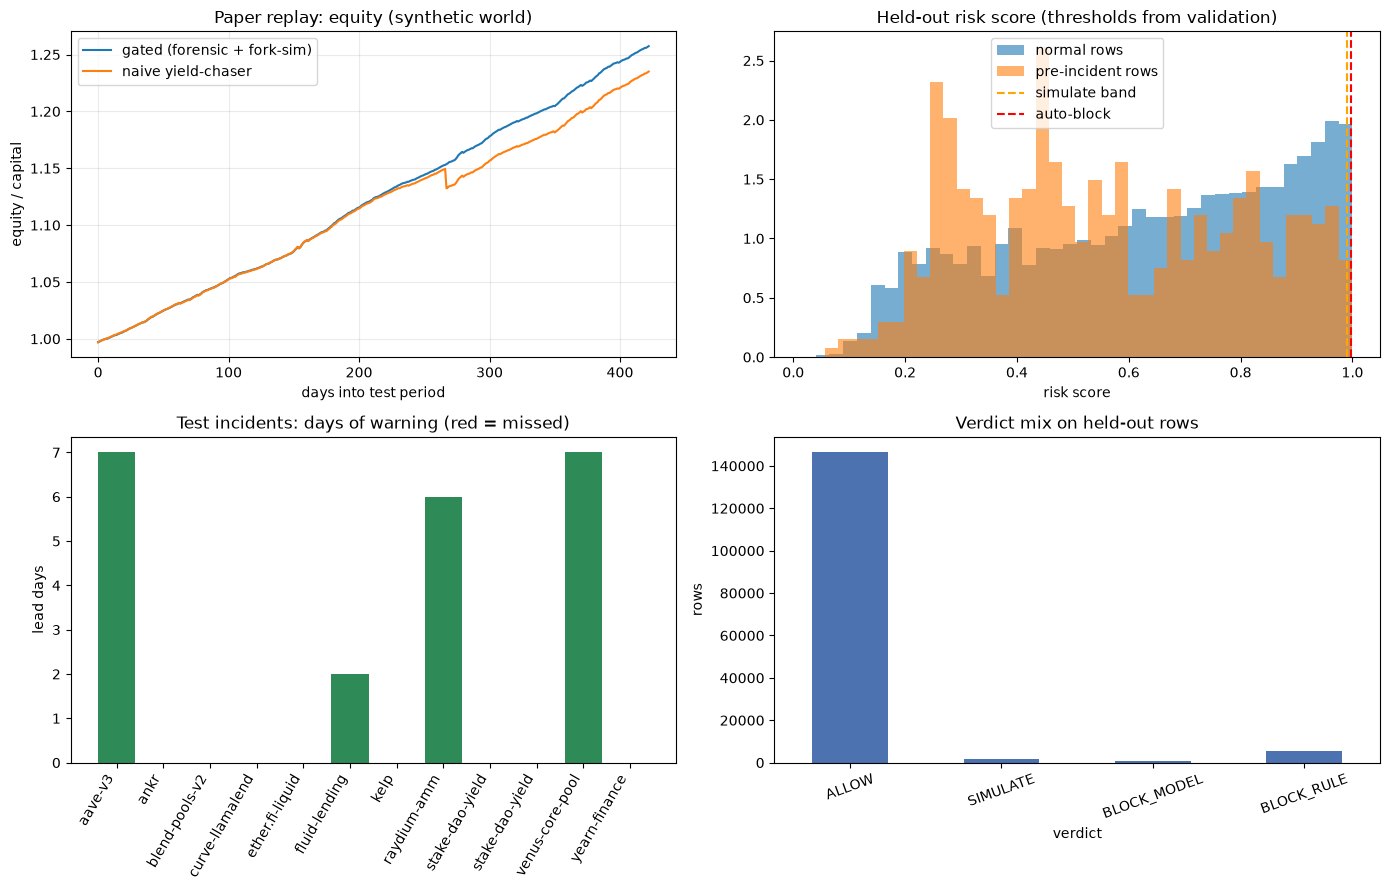

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for n, (eq, _, _) in runs.items():
    ax[0, 0].plot(eq.day_num - eq.day_num.min(), eq.equity / CFG.CAPITAL_USD, label=n)
ax[0, 0].set(title="Paper replay: equity (synthetic world)", xlabel="days into test period", ylabel="equity / capital"); ax[0, 0].legend(); ax[0, 0].grid(alpha=.25)

te = scored[(scored.split == "test") & (~scored.quarantine)]
ax[0, 1].hist(te.loc[te.label == 0, "risk_score"], bins=40, alpha=.6, density=True, label="normal rows")
if te.label.sum() > 0: ax[0, 1].hist(te.loc[te.label == 1, "risk_score"], bins=40, alpha=.6, density=True, label="pre-incident rows")
ax[0, 1].axvline(engine.t_sim, color="orange", ls="--", label="simulate band"); ax[0, 1].axvline(engine.t_block, color="red", ls="--", label="auto-block")
ax[0, 1].set(title="Held-out risk score (thresholds from validation)", xlabel="risk score"); ax[0, 1].legend()

if len(incident_table):
    it = incident_table.assign(lead=incident_table.lead_days.fillna(0))
    ax[1, 0].bar(range(len(it)), it.lead, color=np.where(it.detected, "#2e8b57", "#b44b4b"))
    ax[1, 0].set_xticks(range(len(it))); ax[1, 0].set_xticklabels(it.incident_id.str.split("|").str[0], rotation=60, ha="right")
ax[1, 0].set(title="Test incidents: days of warning (red = missed)", ylabel="lead days")

te.verdict.value_counts().reindex(["ALLOW", "SIMULATE", "BLOCK_MODEL", "BLOCK_RULE"]).fillna(0).plot.bar(ax=ax[1, 1], color="#4c72b0")
ax[1, 1].set(title="Verdict mix on held-out rows", ylabel="rows"); ax[1, 1].tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

## 9 · Running on real data (cost-safe procedure and honest limits)

**Procedure (nothing here has been run against the real endpoints; §7 rehearses every step on a mock server instead)**
1. Config cell: `USE_REAL_DATA=True`, `ALLOW_NETWORK=True`, `MAX_POOLS=60`, `MAX_REQUESTS=250`, `EXCLUDE_FEATURES=("log_tvl",)` (see limit 2). Run the data cell. Every response is cached under `artifacts/raw/`; a crash or the request cap leaves the cache intact and a rerun resumes.
2. **Immediately set `ALLOW_NETWORK=False`** and rerun everything. `USE_REAL_DATA=True` + `ALLOW_NETWORK=False` is served from the cache only (zero requests) and refuses with a clear error on any cache miss. Iterate from here for free; scale `MAX_POOLS` up only after step 3 looks sane.
3. Read `audit_universe` before trusting anything: how many hacks were matched, how many incidents fall in train / test, and its warnings. If train incidents < `MIN_POS_INCIDENTS` the engine stays anomaly-only (`engine.status`); if test incidents < 5, incident-level numbers are anecdotes.
4. Leave `ALIASES = {}`; check `review_queue` (fuzzy name candidates) and add an alias only after reading the source event.
5. Believe only: incident detection vs `placebo_detection` (same-project ordinary windows). Ignore row-level PR-AUC.

**Limits that no code in this notebook can remove**
1. *Survivorship.* The yields catalogue lists currently listed pools; many exploited protocols are gone or drained. `FORCE_INCLUDE_HACKED` recovers the ones still listed, nothing more. Expect tens of matched incidents at best, not hundreds.
2. *Selection on current TVL.* Choosing pools by today's TVL is mild look-ahead, and including every pool of hacked projects shifts the TVL mix of positives vs negatives. A model can then "learn" TVL level. Hence `EXCLUDE_FEATURES=("log_tvl",)` is advised for real runs.
3. *Labels.* A hack record is tied to pools via DeFiLlama ids; a family-level id labels every child protocol. Review matches by eye. Hacks of bridges, CEXs and chains do not map to yield pools at all.
4. *Unverified endpoint details.* Field names (`defillamaId`, `parentProtocol`), response wrapping and whether these endpoints are still free were written from documentation memory and are not tested live. The loader fails loudly on cache miss/HTTP errors and skips pools that error; check `failed=` in its summary line.
5. *Assumptions, not data:* `EXPLOIT_LOSS_FRACTION`, `STRESS`, DEX depth, execution costs. Calibrate before quoting any replay return.

**Deliberately out of scope:** Solidity, wallets, RPC, keeper networks, Tenderly. `SimVault`/`Keeper`/`fork_dry_run` define the interface and invariants a real implementation must satisfy (the §7 tests become your spec).

In [17]:
# ============ DIAGNOSTIC CELL (offline: reads only in-memory frames, no network) ============
# Purpose: separate "the data cannot support this" from "the pipeline is broken".
te  = scored[(scored.split == "test") & (~scored.quarantine)]
neg, pos = te[te.label == 0], te[te.label == 1]

# 1) Who raises alerts on ORDINARY (negative) rows? Rules or the model?
rules = ["apy_above_ceiling", "tvl_below_minimum", "pool_tvl_drawdown", "protocol_tvl_drawdown", "incentive_only_farm"]
src = {r: float(neg.rule_reasons.str.contains(r).mean()) for r in rules}
src["MODEL_ONLY (no rule)"] = float((neg.verdict.isin(["BLOCK_MODEL", "SIMULATE"]) & ~neg.hard_rule).mean())
print("1) share of ordinary test rows alerting, by source:"); print(pd.Series(src).round(4).to_string())

# 2) Is ANY single feature predictive, and does the sign survive train -> test?
def auc(df, f):
    y = df.label.values
    return roc_auc_score(y, df[f].values) if 0 < y.sum() < len(y) else np.nan
tr = scored[(scored.split == "train") & (~scored.quarantine)]
fa = pd.DataFrame({"auc_train": {f: auc(tr, f) for f in FEATURES}, "auc_test": {f: auc(te, f) for f in FEATURES}})
fa["sign_flips"] = (fa.auc_train - 0.5) * (fa.auc_test - 0.5) < 0
print("\n2) single-feature AUC (0.5 = no signal; sign_flips = pattern reverses out of sample):"); print(fa.round(3).to_string())

# 3) What kind of incidents were matched, and how many pools does each label touch?
meta_h = {}
for h in hacks:
    d = int(to_day_num(parse_dates(pd.Series([h.get("date")])))[0]) if h.get("date") is not None else -1
    meta_h[(normalize_name(h.get("name", "")), d)] = (h.get("classification"), h.get("technique"), h.get("amount"))
rows = []
for r in incidents.itertuples(index=False):
    p = scored[scored.incident_id == r.event_id]
    cls, tech, amt = meta_h.get((normalize_name(r.event_name), r.event_day), (None, None, None))
    rows.append(dict(incident=r.event_id, split=getattr(r, "split", ""), pools_labelled=p.pool.nunique(), pos_rows=len(p),
                     classification=cls, technique=tech, amount_usd=amt,
                     max_pool_tvl_drop_7d=float(p.tvl_ret_7.min()) if len(p) else np.nan,
                     max_apy_z=float(p.apy_z_30.max()) if len(p) else np.nan))
print("\n3) matched incidents (pools_labelled >> 1 means the label is protocol-level, not pool-level):")
display(pd.DataFrame(rows).sort_values("pools_labelled", ascending=False))

# 4) Regime shift: universe size, zero-APY share and mean cross-sectional APY rank, per quarter
q = scored.assign(q=pd.to_datetime(scored.day_num, unit="D").dt.to_period("Q"))
print("\n4) composition by quarter:")
print(q.groupby("q").agg(pools=("pool", "nunique"), zero_apy_share=("apy", lambda s: float((s <= 0.0).mean())),
                         median_apy=("apy", "median"), rows=("pool", "size")).round(3).to_string())

# 5) Incident detection WITHOUT the hard rules (what the learned part adds), vs placebo
it = incident_table.copy()
print("\n5) incident table: detected / by_rule / by_model / placebo")
print(it[["incident_id", "pre_window_rows", "detected", "by_rule", "by_model", "placebo_detection"]].round(3).to_string())
n = len(it); k = int(it.detected.sum())
from math import comb
p0 = float(it.placebo_detection.mean())
pval = sum(comb(n, i) * p0**i * (1 - p0)**(n - i) for i in range(k, n + 1))
print(f"\n{k}/{n} detected vs placebo {p0:.2f}: P(>= {k} by chance) = {pval:.2f}  (large = no evidence of skill)")


1) share of ordinary test rows alerting, by source:
apy_above_ceiling        0.0000
tvl_below_minimum        0.0082
pool_tvl_drawdown        0.0260
protocol_tvl_drawdown    0.0093
incentive_only_farm      0.0000
MODEL_ONLY (no rule)     0.0156

2) single-feature AUC (0.5 = no signal; sign_flips = pattern reverses out of sample):
                 auc_train  auc_test  sign_flips
apy                  0.618     0.409        True
log_tvl              0.691     0.560       False
tvl_ret_1            0.528     0.476        True
tvl_ret_7            0.498     0.500       False
tvl_ret_30           0.394     0.452       False
tvl_dd_30            0.442     0.450       False
apy_delta_7          0.488     0.511        True
apy_vol_7            0.606     0.432        True
apy_z_30             0.507     0.474        True
apy_ratio_30         0.647     0.507       False
reward_share         0.732     0.479        True
apy_xs_pct           0.579     0.394        True
proto_tvl_ret_7      0.440     0

,incident,split,pools_labelled,pos_rows,classification,technique,amount_usd,max_pool_tvl_drop_7d,max_apy_z
17,aave-v3|20524,test,50,350,Oracle Manipulation,Oracle Misconfiguration,862000,-0.409180,8.944874
19,fluid-lending|20604,test,12,64,Frontend & Infrastructure,Key Leaked via Infrastructure,215000,-0.336205,10.000000
2,venus-core-pool|20527,test,10,70,Token & Share Accounting,Donation Attack,3700000,-0.389844,7.365583
18,venus-core-pool|20176,val,7,49,Token & Share Accounting,Donation Attack,902000,-0.454325,8.666935
21,curve-dex|19568,train,4,24,Reentrancy,Vyper Compiler Bug,61700000,-0.677771,5.474665
12,raydium-amm|20614,test,2,14,Token & Share Accounting,Infinite Mint,1340000,-0.253375,6.236775
11,yearn-finance|20438,test,2,14,Token & Share Accounting,Donation Attack,300000,-0.211743,0.214366
7,ether.fi-liquid|20707,test,2,14,Access Control,Arbitrary External Call,43260,-0.025404,0.450465
5,curve-dex|19213,train,2,14,Frontend & Infrastructure,DNS Hijack,575000,-0.071033,1.743959
6,curve-llamalend|20514,test,1,7,Token & Share Accounting,Donation Attack,240000,-0.034009,-1.391233



4) composition by quarter:
        pools  zero_apy_share  median_apy   rows
q                                               
2022Q1      6           0.000       0.900    106
2022Q2     18           0.000       5.129   1254
2022Q3     36           0.000       3.900   2454
2022Q4     47           0.088       2.148   3829
2023Q1     65           0.172       1.246   4781
2023Q2     75           0.178       1.018   6147
2023Q3     87           0.186       1.509   7321
2023Q4     95           0.197       1.871   7988
2024Q1    110           0.214       1.745   8999
2024Q2    132           0.186       2.047  10898
2024Q3    149           0.176       2.025  13201
2024Q4    173           0.220       1.892  14596
2025Q1    196           0.229       1.841  16495
2025Q2    218           0.225       1.805  18755
2025Q3    249           0.241       1.382  21423
2025Q4    275           0.257       1.228  24245
2026Q1    362           0.251       1.392  27800
2026Q2    460           0.256       1.721